# 00 - Persiapan Dataset UTS Deep Learning

Notebook ini digunakan untuk:
1. Memeriksa struktur dataset.
2. Memastikan seluruh file tersedia.
3. Memeriksa bentuk dan tipe data.
4. Memastikan dataset siap digunakan untuk Task 1, Task 2, dan Task 3.

In [1]:
# Import Library

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter

# Pengaturan visualisasi
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

print("Semua library berhasil diimpor!")

Semua library berhasil diimpor!


In [2]:
# 1. Menghubungkan Google Drive

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# 2. Mencari File Dataset di Google Drive

import os

for root, dirs, files in os.walk('/content/drive/MyDrive'):
    for file in files:
        if file == "Copy of data_uts_dl.zip":
            print("File ditemukan:", os.path.join(root, file))

File ditemukan: /content/drive/MyDrive/Copy of data_uts_dl.zip


In [4]:
# 3. Mengekstrak Dataset

import zipfile
import os

ZIP_PATH = "/content/drive/MyDrive/Copy of data_uts_dl.zip"
DATA_DIR = "/content/dataset_dl"

os.makedirs(DATA_DIR, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
    zip_ref.extractall(DATA_DIR)

print("Dataset berhasil diekstrak!")
print("\nIsi folder dataset:")

for item in sorted(os.listdir(DATA_DIR)):
    print("-", item)

Dataset berhasil diekstrak!

Isi folder dataset:
- clustering.npz
- clustering_meta.csv
- kamus_data.md
- klasifikasi_test.npz
- klasifikasi_test_meta.csv
- klasifikasi_train.npz
- klasifikasi_train_meta.csv
- rul_test.csv.gz
- rul_train.csv.gz


In [5]:
# 4. Memeriksa Kelengkapan Dataset

required_files = [
    "klasifikasi_train.npz",
    "klasifikasi_test.npz",
    "klasifikasi_train_meta.csv",
    "klasifikasi_test_meta.csv",
    "rul_train.csv.gz",
    "rul_test.csv.gz",
    "clustering.npz",
    "clustering_meta.csv",
    "kamus_data.md"
]

for file in required_files:
    path = os.path.join(DATA_DIR, file)
    status = "Tersedia" if os.path.exists(path) else "Tidak ditemukan"
    print(f"{file}: {status}")

klasifikasi_train.npz: Tersedia
klasifikasi_test.npz: Tersedia
klasifikasi_train_meta.csv: Tersedia
klasifikasi_test_meta.csv: Tersedia
rul_train.csv.gz: Tersedia
rul_test.csv.gz: Tersedia
clustering.npz: Tersedia
clustering_meta.csv: Tersedia
kamus_data.md: Tersedia


In [6]:
# 5. Memeriksa Struktur Dataset

# Task 1 - Classification
data_train = np.load(os.path.join(DATA_DIR, "klasifikasi_train.npz"))
data_test = np.load(os.path.join(DATA_DIR, "klasifikasi_test.npz"))

print("=== TASK 1: CLASSIFICATION ===")
for key in data_train.files:
    print(f"Train {key}: {data_train[key].shape} | {data_train[key].dtype}")

for key in data_test.files:
    print(f"Test {key}: {data_test[key].shape} | {data_test[key].dtype}")


# Task 2 - RUL Regression
rul_train = pd.read_csv(os.path.join(DATA_DIR, "rul_train.csv.gz"))
rul_test = pd.read_csv(os.path.join(DATA_DIR, "rul_test.csv.gz"))

print("\n=== TASK 2: RUL REGRESSION ===")
print("Train:", rul_train.shape)
print("Test :", rul_test.shape)
print("Kolom:", rul_train.columns.tolist())


# Task 3 - Clustering
data_cluster = np.load(os.path.join(DATA_DIR, "clustering.npz"))

print("\n=== TASK 3: CLUSTERING ===")
for key in data_cluster.files:
    print(f"{key}: {data_cluster[key].shape} | {data_cluster[key].dtype}")

=== TASK 1: CLASSIFICATION ===
Train gambar: (48000, 64, 64) | uint8
Train sensor: (48000, 3, 128) | float16
Test gambar: (16000, 64, 64) | uint8
Test sensor: (16000, 3, 128) | float16

=== TASK 2: RUL REGRESSION ===
Train: (254174, 26)
Test : (51692, 26)
Kolom: ['id_unit', 'siklus', 'setel_1', 'setel_2', 'setel_3', 's01', 's02', 's03', 's04', 's05', 's06', 's07', 's08', 's09', 's10', 's11', 's12', 's13', 's14', 's15', 's16', 's17', 's18', 's19', 's20', 's21']

=== TASK 3: CLUSTERING ===
gambar: (36000, 64, 64) | uint8
spektrum: (36000, 128) | float16


In [7]:
# 6. Memeriksa Metadata

metadata_files = [
    "klasifikasi_train_meta.csv",
    "klasifikasi_test_meta.csv",
    "clustering_meta.csv"
]

for file in metadata_files:
    df = pd.read_csv(os.path.join(DATA_DIR, file))

    print(f"\n=== {file} ===")
    print("Shape:", df.shape)
    display(df.head())


=== klasifikasi_train_meta.csv ===
Shape: (48000, 7)


,indeks,id_unit,lini,shift,id_mesin,batch_material,kelas
0,0,U384670,A,pagi,M05,B135,gores
1,1,U487023,A,malam,M04,B146,gores
2,2,U327240,B,pagi,M09,B003,normal
3,3,U696502,A,siang,M06,B085,noda
4,4,U272751,B,siang,M08,B106,normal



=== klasifikasi_test_meta.csv ===
Shape: (16000, 6)


,indeks,id_unit,lini,shift,id_mesin,batch_material
0,0,U412019,A,pagi,M01,B136
1,1,U929275,A,pagi,M01,B095
2,2,U845264,A,pagi,M01,B029
3,3,U382231,B,pagi,M08,B058
4,4,U156089,B,pagi,M12,B139



=== clustering_meta.csv ===
Shape: (36000, 3)


,indeks,id_sampel,mikroskop
0,0,S966119,M1
1,1,S315633,M2
2,2,S805122,M1
3,3,S467543,M1
4,4,S475842,M1


# TASK 1 - MULTIMODAL CLASSIFICATION

## 1. Exploratory Data Analysis (EDA)

EDA dilakukan untuk memahami karakteristik dataset klasifikasi produk, meliputi:
- Distribusi kelas produk.
- Distribusi lini produksi.
- Visualisasi citra produk.
- Karakteristik sinyal sensor.
- Analisis missing value.

In [8]:
# 7. Memuat Data Task 1

# Dataset utama
classification_train = np.load(
    os.path.join(DATA_DIR, "klasifikasi_train.npz")
)

classification_test = np.load(
    os.path.join(DATA_DIR, "klasifikasi_test.npz")
)

# Metadata
train_meta = pd.read_csv(
    os.path.join(DATA_DIR, "klasifikasi_train_meta.csv")
)

test_meta = pd.read_csv(
    os.path.join(DATA_DIR, "klasifikasi_test_meta.csv")
)

# Memisahkan gambar dan sensor
X_image = classification_train["gambar"]
X_sensor = classification_train["sensor"]

X_image_test = classification_test["gambar"]
X_sensor_test = classification_test["sensor"]

# Label kelas
y = train_meta["kelas"]

print("Data Task 1 berhasil dimuat!")
print("Gambar train :", X_image.shape)
print("Sensor train :", X_sensor.shape)
print("Gambar test  :", X_image_test.shape)
print("Sensor test  :", X_sensor_test.shape)
print("Jumlah label :", len(y))

Data Task 1 berhasil dimuat!
Gambar train : (48000, 64, 64)
Sensor train : (48000, 3, 128)
Gambar test  : (16000, 64, 64)
Sensor test  : (16000, 3, 128)
Jumlah label : 48000


## 1.1 Distribusi Kelas Produk

Analisis distribusi kelas dilakukan untuk mengetahui jumlah sampel pada setiap kategori produk.

Analisis ini juga digunakan untuk mengidentifikasi kemungkinan ketidakseimbangan kelas (class imbalance).

Jumlah data setiap kelas:


,Jumlah Sampel
kelas,
normal,23888
gores,5623
noda,4773
las_dingin,4323
retak,3606
gelembung,3430
kontaminasi,2357


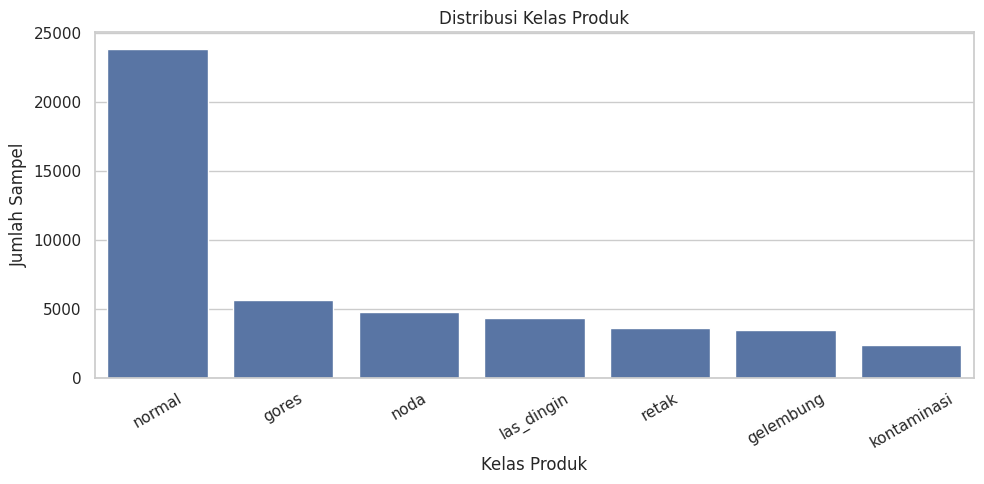

In [9]:
# 8. Distribusi Kelas Produk

class_counts = y.value_counts()

print("Jumlah data setiap kelas:")
display(class_counts.to_frame(name="Jumlah Sampel"))

plt.figure(figsize=(10, 5))

sns.barplot(
    x=class_counts.index,
    y=class_counts.values
)

plt.title("Distribusi Kelas Produk")
plt.xlabel("Kelas Produk")
plt.ylabel("Jumlah Sampel")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

### Interpretasi Distribusi Kelas

Berdasarkan hasil analisis, dataset memiliki distribusi kelas yang tidak seimbang (class imbalance). Kelas normal merupakan kelas dengan jumlah sampel terbanyak, yaitu 23.888 sampel (49,77%), sedangkan kelas kontaminasi memiliki jumlah sampel paling sedikit, yaitu 2.357 sampel (4,91%).

Ketidakseimbangan ini berpotensi menyebabkan model lebih cenderung memprediksi kelas mayoritas. Oleh karena itu, evaluasi model akan menggunakan macro-F1 untuk memperhatikan performa pada seluruh kelas secara seimbang.

## 1.2 Distribusi Lini Produksi (Production Line)

Analisis ini bertujuan untuk membandingkan distribusi sampel dari lini produksi A dan B pada dataset training dan testing.

Perbedaan distribusi dapat menunjukkan adanya potensi domain shift antara data training dan testing.

,Train (Jumlah),Train (%),Test (Jumlah),Test (%)
lini,,,,
A,35964,74.92,6393,39.96
B,12036,25.07,9607,60.04


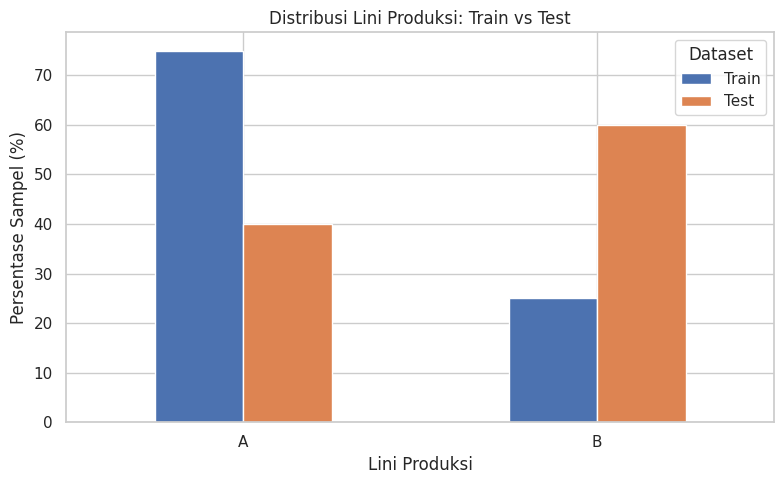

In [10]:
# 9. Analisis Distribusi Lini Produksi

# Menghitung jumlah sampel
train_line = train_meta["lini"].value_counts().sort_index()
test_line = test_meta["lini"].value_counts().sort_index()

# Menghitung persentase
train_line_pct = train_meta["lini"].value_counts(normalize=True).sort_index() * 100
test_line_pct = test_meta["lini"].value_counts(normalize=True).sort_index() * 100

# Menggabungkan hasil
line_comparison = pd.DataFrame({
    "Train (Jumlah)": train_line,
    "Train (%)": train_line_pct,
    "Test (Jumlah)": test_line,
    "Test (%)": test_line_pct
})

display(line_comparison.round(2))

# Visualisasi
line_plot = pd.DataFrame({
    "Train": train_line_pct,
    "Test": test_line_pct
})

line_plot.plot(kind="bar", figsize=(8, 5))

plt.title("Distribusi Lini Produksi: Train vs Test")
plt.xlabel("Lini Produksi")
plt.ylabel("Persentase Sampel (%)")
plt.xticks(rotation=0)
plt.legend(title="Dataset")
plt.tight_layout()
plt.show()

### Interpretasi Distribusi Lini Produksi

Berdasarkan hasil analisis, terdapat perbedaan distribusi lini produksi antara dataset training dan testing.

Pada dataset training, lini A mendominasi dengan proporsi 74,92%, sedangkan lini B sebesar 25,07%. Sebaliknya, pada dataset testing, lini B memiliki proporsi terbesar yaitu 60,04%, sementara lini A sebesar 39,96%.

Perbedaan proporsi ini menunjukkan adanya potensi domain shift berdasarkan lini produksi. Kondisi tersebut perlu diperhatikan karena model yang dilatih pada distribusi training mungkin menghadapi karakteristik data yang berbeda ketika melakukan prediksi pada dataset testing.

Oleh karena itu, evaluasi domain shift berdasarkan lini produksi akan dilakukan pada tahap eksperimen model.

## 1.3 Visualisasi Citra Produk

Visualisasi dilakukan untuk mengamati karakteristik citra dari setiap kategori produk.

Setiap kelas akan diwakili oleh beberapa contoh citra agar dapat diamati perbedaan pola visual antar kelas.

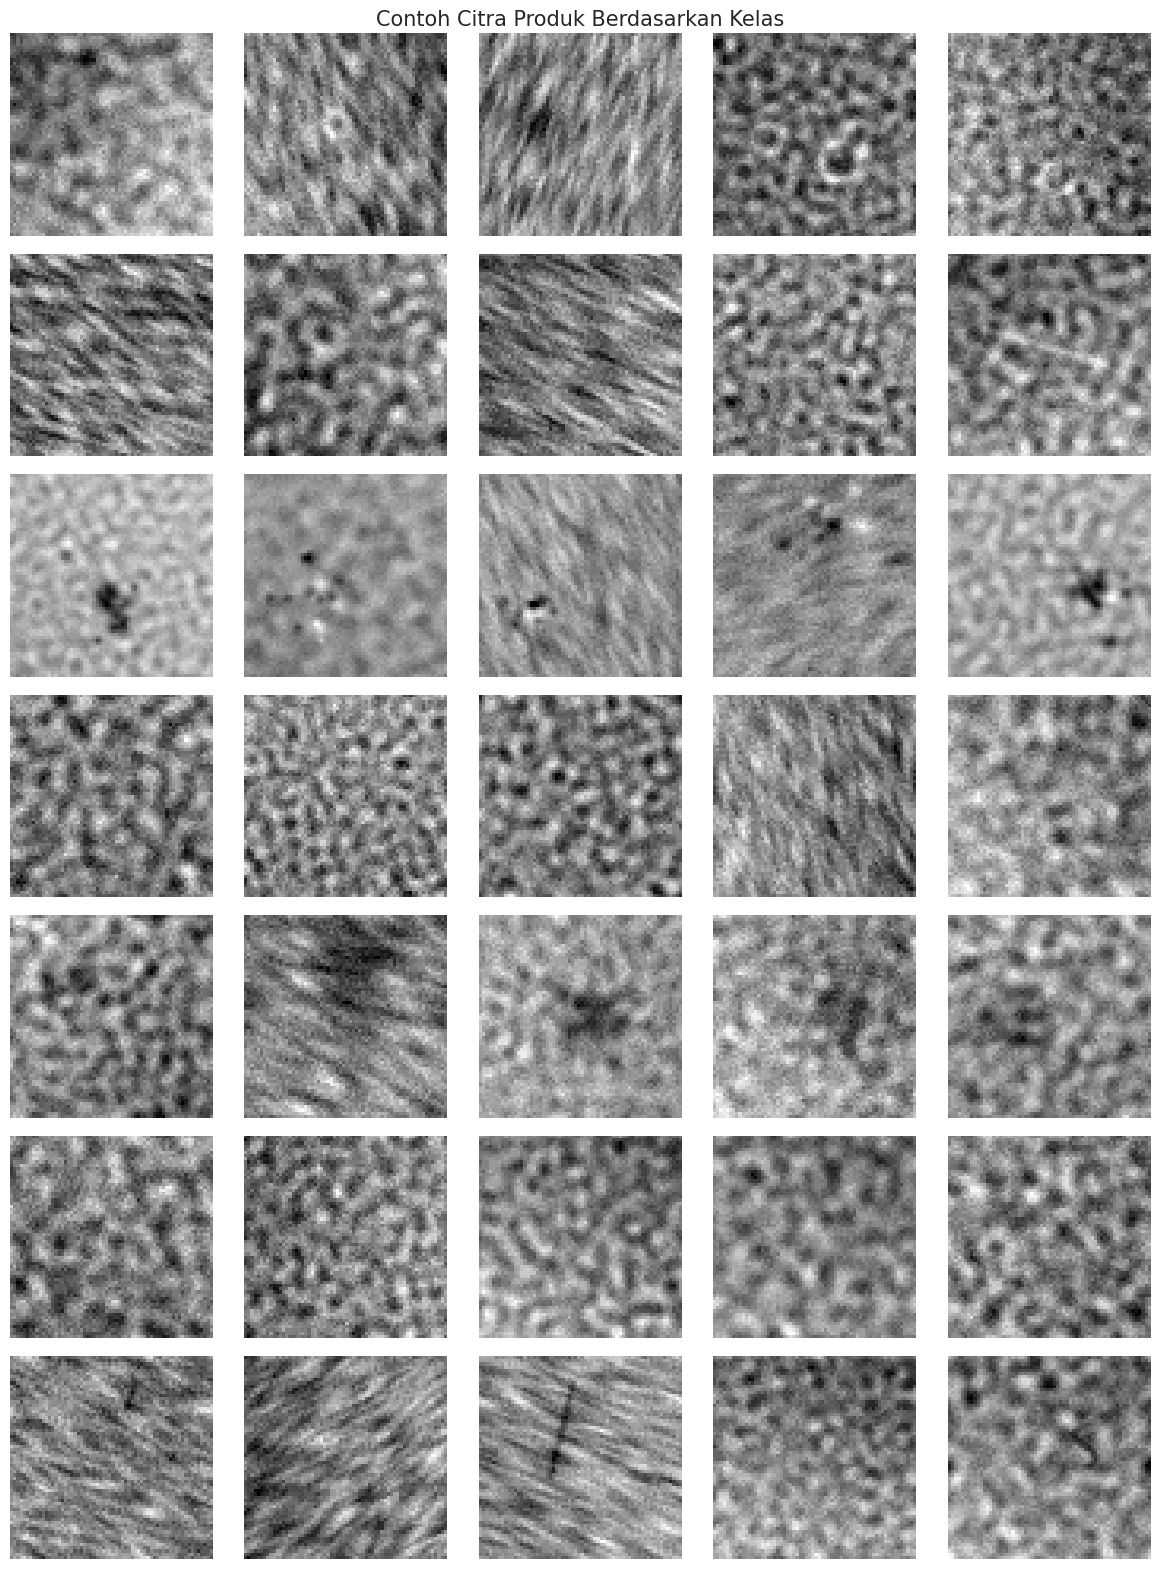

In [11]:
# 10. Visualisasi Contoh Citra Setiap Kelas

classes = sorted(y.unique())

fig, axes = plt.subplots(
    nrows=len(classes),
    ncols=5,
    figsize=(12, 16)
)

for row, class_name in enumerate(classes):

    # Mengambil indeks sampel dari kelas tertentu
    class_indices = np.where(y.values == class_name)[0]

    # Mengambil 5 sampel secara acak
    selected_indices = np.random.choice(
        class_indices,
        size=5,
        replace=False
    )

    for col, idx in enumerate(selected_indices):

        axes[row, col].imshow(X_image[idx], cmap="gray")
        axes[row, col].axis("off")

        if col == 0:
            axes[row, col].set_ylabel(
                class_name,
                fontsize=11
            )

plt.suptitle(
    "Contoh Citra Produk Berdasarkan Kelas",
    fontsize=15
)

plt.tight_layout()
plt.show()

### Interpretasi Visualisasi Citra

Berdasarkan visualisasi sampel dari tujuh kelas produk, terlihat adanya variasi karakteristik tekstur pada setiap citra. Beberapa citra menunjukkan pola granular dan bintik-bintik, sedangkan citra lainnya memiliki pola garis memanjang maupun diagonal.

Selain itu, terdapat kemiripan karakteristik visual antar beberapa sampel. Hal ini menunjukkan bahwa proses klasifikasi mungkin membutuhkan kemampuan model untuk mempelajari fitur tekstur dan pola lokal secara lebih mendalam.

Oleh karena itu, CNN akan digunakan sebagai image encoder untuk mengekstraksi fitur visual dari citra produk.

## 1.4 Analisis Sinyal Sensor

Analisis ini bertujuan untuk memahami karakteristik sinyal sensor yang menyertai setiap sampel produk.

Dataset memiliki tiga kanal sensor, yaitu temperatur, getaran, dan arus listrik. Setiap kanal terdiri dari 128 titik pengukuran.

Analisis dilakukan dengan mengamati pola perubahan sinyal pada beberapa sampel dari setiap kelas.

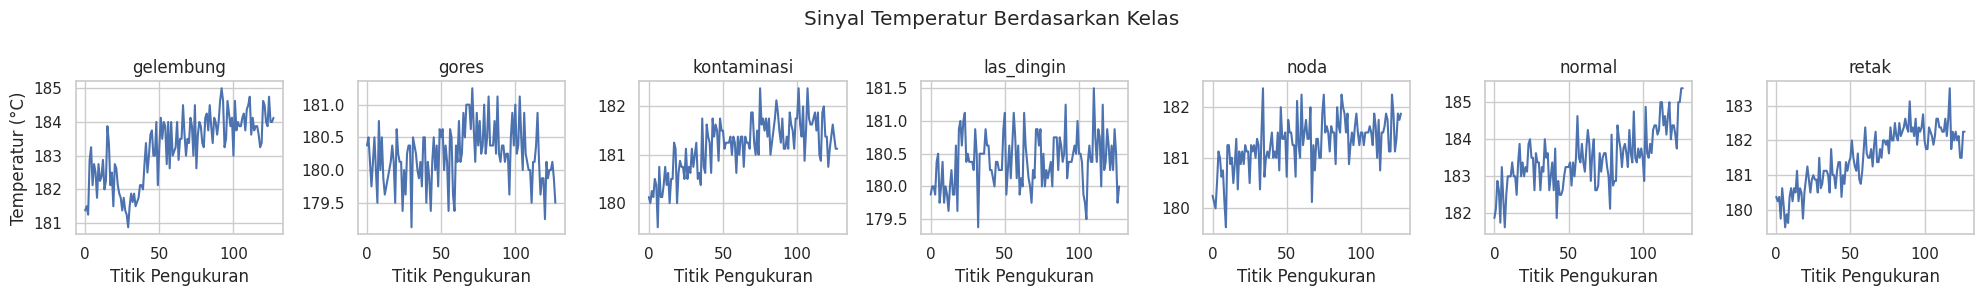

In [12]:
# 11A. Visualisasi Sinyal Temperatur

fig, axes = plt.subplots(1, 7, figsize=(20, 3))

for col, class_name in enumerate(classes):
    idx = np.where(y.values == class_name)[0][0]

    axes[col].plot(X_sensor[idx, 0, :])
    axes[col].set_title(class_name)
    axes[col].set_xlabel("Titik Pengukuran")

axes[0].set_ylabel("Temperatur (°C)")

plt.suptitle("Sinyal Temperatur Berdasarkan Kelas")
plt.tight_layout()
plt.show()

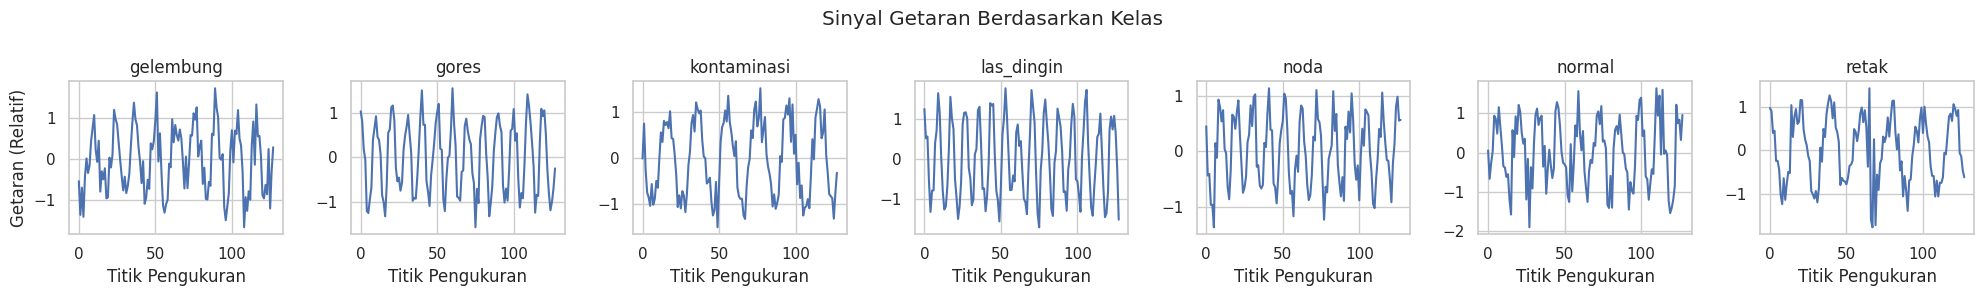

In [13]:
# 11B. Visualisasi Sinyal Getaran

fig, axes = plt.subplots(1, 7, figsize=(20, 3))

for col, class_name in enumerate(classes):
    idx = np.where(y.values == class_name)[0][0]

    axes[col].plot(X_sensor[idx, 1, :])
    axes[col].set_title(class_name)
    axes[col].set_xlabel("Titik Pengukuran")

axes[0].set_ylabel("Getaran (Relatif)")

plt.suptitle("Sinyal Getaran Berdasarkan Kelas")
plt.tight_layout()
plt.show()

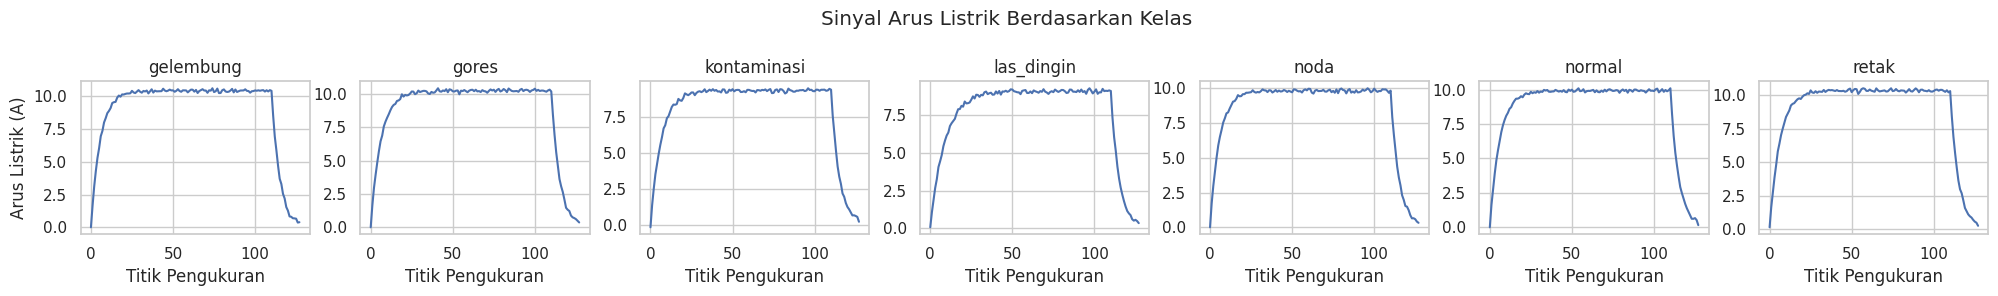

In [14]:
# 11C. Visualisasi Sinyal Arus Listrik

fig, axes = plt.subplots(1, 7, figsize=(20, 3))

for col, class_name in enumerate(classes):
    idx = np.where(y.values == class_name)[0][0]

    axes[col].plot(X_sensor[idx, 2, :])
    axes[col].set_title(class_name)
    axes[col].set_xlabel("Titik Pengukuran")

axes[0].set_ylabel("Arus Listrik (A)")

plt.suptitle("Sinyal Arus Listrik Berdasarkan Kelas")
plt.tight_layout()
plt.show()

### Interpretasi Karakteristik Sinyal Sensor

Berdasarkan visualisasi sinyal sensor, ditemukan bahwa setiap kanal memiliki karakteristik pola yang berbeda.

1. Temperatur menunjukkan kecenderungan peningkatan dan kestabilan dengan beberapa fluktuasi.
2. Getaran menunjukkan pola fluktuasi yang berulang dengan variasi amplitudo.
3. Arus listrik menunjukkan pola peningkatan pada awal pengukuran, kondisi relatif stabil, dan penurunan pada akhir pengukuran.

Pada sampel yang diamati, pola arus listrik terlihat relatif serupa antar kelas. Sementara itu, temperatur dan getaran menunjukkan variasi yang perlu dianalisis lebih lanjut.

Visualisasi ini masih bersifat eksploratif karena hanya menggunakan satu sampel dari setiap kelas. Oleh karena itu, diperlukan analisis terhadap keseluruhan dataset untuk mengetahui hubungan sinyal sensor dengan kategori produk.

## 1.5 Analisis Missing Value pada Sensor

Analisis missing value dilakukan untuk mengetahui jumlah dan persentase nilai yang hilang pada setiap kanal sensor.

Dataset memiliki tiga kanal sensor:
1. Temperatur
2. Getaran
3. Arus listrik

Hasil analisis akan digunakan sebagai dasar dalam menentukan strategi preprocessing dan pengujian missing modality.

,Sensor,Jumlah Missing,Total Nilai,Persentase Missing (%)
0,Temperatur,365824,6144000,5.95
1,Getaran,364416,6144000,5.93
2,Arus Listrik,366336,6144000,5.96


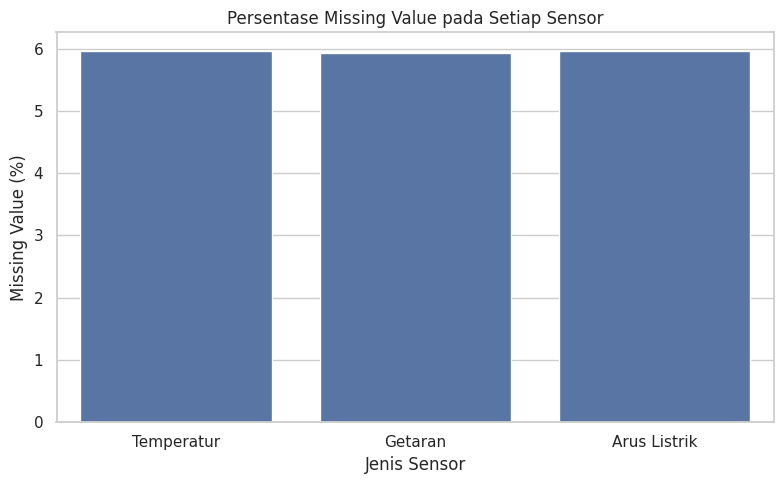

In [15]:
# 12. Analisis Missing Value pada Setiap Sensor

sensor_names = ["Temperatur", "Getaran", "Arus Listrik"]

missing_count = np.isnan(X_sensor).sum(axis=(0, 2))
total_values = X_sensor.shape[0] * X_sensor.shape[2]
missing_percentage = (missing_count / total_values) * 100

missing_summary = pd.DataFrame({
    "Sensor": sensor_names,
    "Jumlah Missing": missing_count,
    "Total Nilai": total_values,
    "Persentase Missing (%)": missing_percentage
})

display(missing_summary.round(2))

# Visualisasi
plt.figure(figsize=(8, 5))

sns.barplot(
    data=missing_summary,
    x="Sensor",
    y="Persentase Missing (%)"
)

plt.title("Persentase Missing Value pada Setiap Sensor")
plt.xlabel("Jenis Sensor")
plt.ylabel("Missing Value (%)")
plt.tight_layout()
plt.show()

In [16]:
# 13. Analisis Sampel dengan Sensor Hilang

missing_per_sample = np.isnan(X_sensor).any(axis=(1, 2))

total_samples = len(X_sensor)
samples_with_missing = missing_per_sample.sum()
samples_without_missing = total_samples - samples_with_missing

print("Total sampel:", total_samples)
print("Sampel dengan sensor hilang:", samples_with_missing)
print("Sampel tanpa sensor hilang:", samples_without_missing)
print(
    "Persentase sampel dengan sensor hilang:",
    round(samples_with_missing / total_samples * 100, 2),
    "%"
)

Total sampel: 48000
Sampel dengan sensor hilang: 3863
Sampel tanpa sensor hilang: 44137
Persentase sampel dengan sensor hilang: 8.05 %


,Kelas,Missing Value (%)
0,gelembung,6.07
1,gores,6.28
2,kontaminasi,5.15
3,las_dingin,5.68
4,noda,6.05
5,normal,5.87
6,retak,6.53


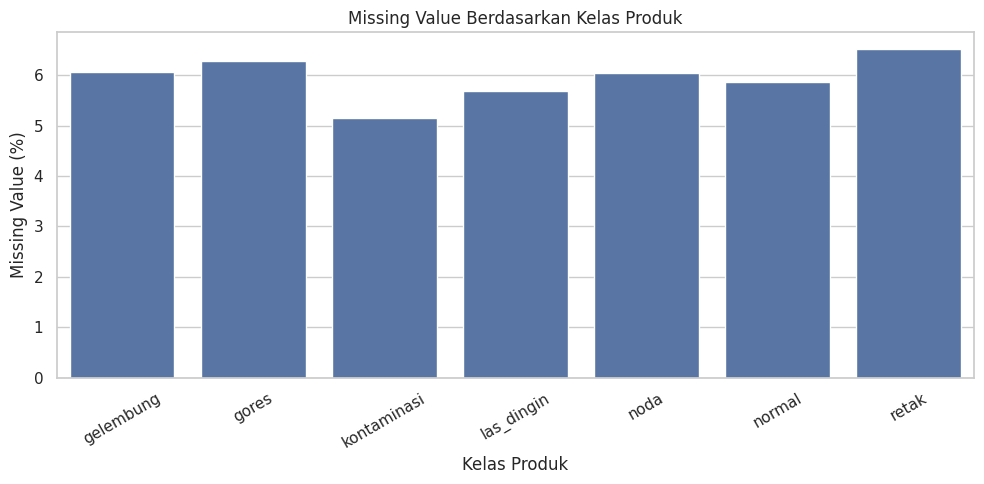

In [17]:
# 14. Missing Value Berdasarkan Kelas

missing_by_class = []

for class_name in classes:

    class_indices = np.where(y.values == class_name)[0]
    class_sensor = X_sensor[class_indices]

    missing_percentage = (
        np.isnan(class_sensor).mean() * 100
    )

    missing_by_class.append({
        "Kelas": class_name,
        "Missing Value (%)": missing_percentage
    })

missing_class_df = pd.DataFrame(missing_by_class)

display(missing_class_df.round(2))

# Visualisasi
plt.figure(figsize=(10, 5))

sns.barplot(
    data=missing_class_df,
    x="Kelas",
    y="Missing Value (%)"
)

plt.title("Missing Value Berdasarkan Kelas Produk")
plt.xlabel("Kelas Produk")
plt.ylabel("Missing Value (%)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

### Interpretasi Missing Value

Berdasarkan hasil analisis, ketiga kanal sensor memiliki persentase missing value yang relatif seragam. Temperatur memiliki missing value sebesar 5,95%, getaran sebesar 5,93%, dan arus listrik sebesar 5,96%.

Dari total 48.000 sampel, terdapat 3.863 sampel (8,05%) yang memiliki setidaknya satu nilai sensor hilang, sedangkan 44.137 sampel (91,95%) tidak memiliki nilai yang hilang.

Berdasarkan kategori produk, kelas retak memiliki persentase missing value tertinggi sebesar 6,53%, sedangkan kelas kontaminasi memiliki persentase terendah sebesar 5,15%.

Temuan ini menunjukkan bahwa missing value perlu ditangani sebelum proses pelatihan model. Strategi preprocessing akan mempertahankan sampel yang tersedia dengan melakukan penanganan nilai yang hilang pada sinyal sensor.

## 1.6 Statistik Deskriptif Sinyal Sensor

Analisis statistik deskriptif dilakukan untuk memahami distribusi nilai pada setiap kanal sensor.

Parameter yang dianalisis meliputi nilai minimum, maksimum, rata-rata, dan standar deviasi. Nilai NaN diabaikan dalam perhitungan statistik.

In [18]:
# 15. Statistik Deskriptif Sensor

sensor_names = ["Temperatur", "Getaran", "Arus Listrik"]

sensor_statistics = []

for i, sensor_name in enumerate(sensor_names):

    values = X_sensor[:, i, :].astype(np.float32).flatten()

    sensor_statistics.append({
        "Sensor": sensor_name,
        "Minimum": np.nanmin(values),
        "Maksimum": np.nanmax(values),
        "Rata-rata": np.nanmean(values),
        "Standar Deviasi": np.nanstd(values)
    })

sensor_stats_df = pd.DataFrame(sensor_statistics)

display(sensor_stats_df.round(4))

,Sensor,Minimum,Maksimum,Rata-rata,Standar Deviasi
0,Temperatur,175.0000,187.2500,181.619995,1.1195
1,Getaran,-4.4766,3.8477,0.000200,0.7916
2,Arus Listrik,-0.3264,11.1953,8.458500,2.9546


## 1.7 Distribusi dan Analisis Nilai Ekstrem Sensor

Analisis dilakukan untuk melihat distribusi nilai pada setiap kanal sensor serta mengidentifikasi kemungkinan adanya nilai ekstrem (outlier).

Visualisasi menggunakan histogram dan boxplot dengan mengabaikan nilai NaN.

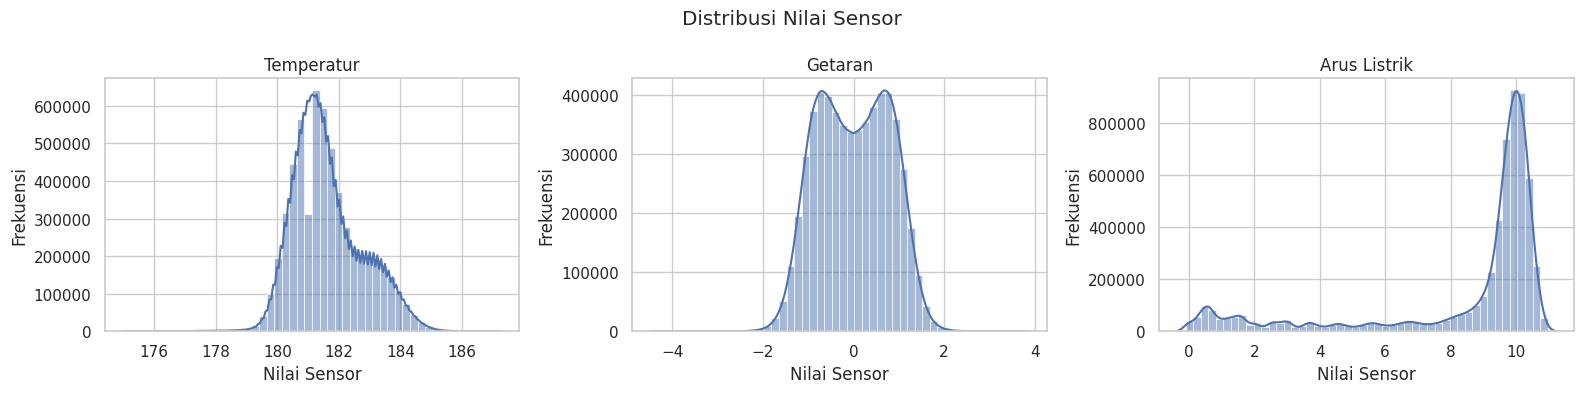

In [19]:
# 16. Distribusi Nilai Setiap Sensor

sensor_names = ["Temperatur", "Getaran", "Arus Listrik"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for i, sensor_name in enumerate(sensor_names):

    values = X_sensor[:, i, :].astype(np.float32).flatten()
    values = values[~np.isnan(values)]

    sns.histplot(
        values,
        bins=50,
        kde=True,
        ax=axes[i]
    )

    axes[i].set_title(sensor_name)
    axes[i].set_xlabel("Nilai Sensor")
    axes[i].set_ylabel("Frekuensi")

plt.suptitle("Distribusi Nilai Sensor")
plt.tight_layout()
plt.show()

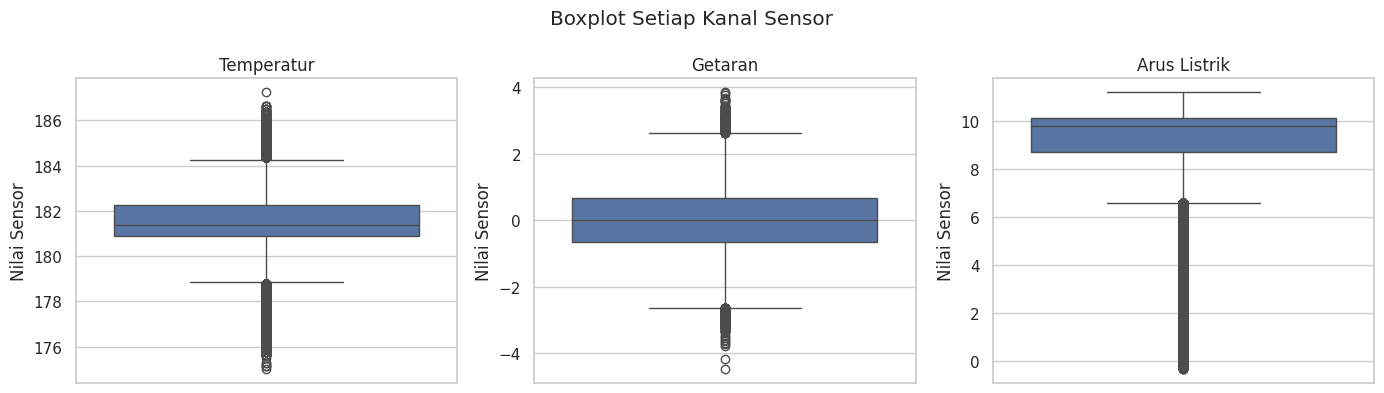

In [20]:
# 17. Analisis Nilai Ekstrem Sensor

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for i, sensor_name in enumerate(sensor_names):

    values = X_sensor[:, i, :].astype(np.float32).flatten()
    values = values[~np.isnan(values)]

    sns.boxplot(
        y=values,
        ax=axes[i]
    )

    axes[i].set_title(sensor_name)
    axes[i].set_ylabel("Nilai Sensor")

plt.suptitle("Boxplot Setiap Kanal Sensor")
plt.tight_layout()
plt.show()

### Interpretasi Distribusi dan Nilai Ekstrem Sensor

Berdasarkan histogram, temperatur memiliki konsentrasi nilai terbesar di sekitar 181–182 °C. Sinyal getaran tersebar di sekitar nol dengan pola distribusi yang memiliki dua area puncak. Sementara itu, arus listrik memiliki konsentrasi nilai terbesar di sekitar 9–10 A dengan ekor distribusi menuju nilai yang lebih rendah.

Hasil boxplot menunjukkan adanya sejumlah nilai ekstrem pada ketiga kanal sensor. Nilai ekstrem tersebut tidak langsung dianggap sebagai kesalahan data karena dapat merepresentasikan variasi kondisi operasional.

Oleh karena itu, nilai ekstrem akan dipertahankan terlebih dahulu dan penanganan data akan difokuskan pada missing value serta normalisasi sinyal sensor.

## 2. Data Preprocessing

Tahap preprocessing dilakukan untuk mempersiapkan data sebelum digunakan dalam pelatihan model Deep Learning.

### 2.1 Label Encoding

Label kelas produk diubah dari kategori teks menjadi representasi numerik agar dapat diproses oleh model klasifikasi.

In [21]:
# 18. Label Encoding

class_names = sorted(y.unique())

class_to_idx = {
    class_name: idx
    for idx, class_name in enumerate(class_names)
}

idx_to_class = {
    idx: class_name
    for class_name, idx in class_to_idx.items()
}

y_encoded = y.map(class_to_idx).values

print("Mapping Label:")
for class_name, idx in class_to_idx.items():
    print(f"{class_name}: {idx}")

print("\nBentuk label:", y_encoded.shape)
print("Contoh label:", y_encoded[:10])

Mapping Label:
gelembung: 0
gores: 1
kontaminasi: 2
las_dingin: 3
noda: 4
normal: 5
retak: 6

Bentuk label: (48000,)
Contoh label: [1 1 5 4 5 3 1 0 1 5]


### 2.2 Image Normalization

Citra produk memiliki ukuran 64 × 64 piksel dengan tipe data uint8.

Normalisasi dilakukan dengan membagi nilai piksel dengan 255 sehingga seluruh nilai berada pada rentang 0 hingga 1.

In [22]:
# 19. Normalisasi Citra

# Mengubah tipe data menjadi float32
X_image_normalized = X_image.astype(np.float32) / 255.0

# Normalisasi citra test
X_image_test_normalized = X_image_test.astype(np.float32) / 255.0

print("Tipe data:", X_image_normalized.dtype)
print("Rentang nilai minimum:", X_image_normalized.min())
print("Rentang nilai maksimum:", X_image_normalized.max())

print("Shape citra train:", X_image_normalized.shape)
print("Shape citra test:", X_image_test_normalized.shape)

Tipe data: float32
Rentang nilai minimum: 0.0
Rentang nilai maksimum: 1.0
Shape citra train: (48000, 64, 64)
Shape citra test: (16000, 64, 64)


### 2.3 Training and Validation Split

Dataset training dibagi menjadi 80% data training dan 20% data validation menggunakan stratified split.

Pembagian ini bertujuan menjaga proporsi setiap kelas pada kedua subset.

Dataset testing tetap dipisahkan untuk evaluasi akhir model.

In [23]:
# 20. Membagi Data Training dan Validation

from sklearn.model_selection import train_test_split

# Indeks seluruh sampel
indices = np.arange(len(y_encoded))

# Stratified split
train_idx, val_idx = train_test_split(
    indices,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

# Membagi citra
X_image_train = X_image_normalized[train_idx]
X_image_val = X_image_normalized[val_idx]

# Membagi label
y_train = y_encoded[train_idx]
y_val = y_encoded[val_idx]

# Membagi metadata
train_meta_split = train_meta.iloc[train_idx].reset_index(drop=True)
val_meta_split = train_meta.iloc[val_idx].reset_index(drop=True)

print("Jumlah data training:", len(train_idx))
print("Jumlah data validation:", len(val_idx))

print("\nShape citra training:", X_image_train.shape)
print("Shape citra validation:", X_image_val.shape)

print("\nShape label training:", y_train.shape)
print("Shape label validation:", y_val.shape)

Jumlah data training: 38400
Jumlah data validation: 9600

Shape citra training: (38400, 64, 64)
Shape citra validation: (9600, 64, 64)

Shape label training: (38400,)
Shape label validation: (9600,)


In [24]:
# 21. Memeriksa Distribusi Label Training dan Validation

train_distribution = pd.Series(y_train).value_counts().sort_index()
val_distribution = pd.Series(y_val).value_counts().sort_index()

distribution_check = pd.DataFrame({
    "Kelas": [idx_to_class[i] for i in range(len(class_names))],
    "Training": [
        train_distribution.get(i, 0)
        for i in range(len(class_names))
    ],
    "Validation": [
        val_distribution.get(i, 0)
        for i in range(len(class_names))
    ]
})

display(distribution_check)

,Kelas,Training,Validation
0,gelembung,2744,686
1,gores,4499,1124
2,kontaminasi,1886,471
3,las_dingin,3458,865
4,noda,3818,955
5,normal,19110,4778
6,retak,2885,721


## 2.4 Sensor Data Preparation

Data sensor dipersiapkan untuk digunakan oleh sensor encoder.

Tahapan preprocessing meliputi:
1. Membagi data sensor berdasarkan indeks training dan validation yang telah dibuat.
2. Memeriksa missing value.
3. Menangani nilai yang hilang.
4. Melakukan standardisasi setiap kanal sensor.

Pembagian indeks disamakan dengan data citra agar setiap sampel memiliki pasangan data multimodal yang sesuai.

In [25]:
# 22. Membagi Data Sensor

# Menggunakan indeks split yang sama dengan data citra
X_sensor_train_raw = X_sensor[train_idx]
X_sensor_val_raw = X_sensor[val_idx]

# Data test tetap terpisah
X_sensor_test_raw = X_sensor_test

print("Sensor training:", X_sensor_train_raw.shape)
print("Sensor validation:", X_sensor_val_raw.shape)
print("Sensor testing:", X_sensor_test_raw.shape)

print("\nMissing value:")
print("Training:", np.isnan(X_sensor_train_raw).sum())
print("Validation:", np.isnan(X_sensor_val_raw).sum())
print("Testing:", np.isnan(X_sensor_test_raw).sum())

Sensor training: (38400, 3, 128)
Sensor validation: (9600, 3, 128)
Sensor testing: (16000, 3, 128)

Missing value:
Training: 884480
Validation: 212096
Testing: 374272


In [26]:
# 23. Memeriksa Kanal Sensor yang Sepenuhnya Kosong

for name, data in [
    ("Training", X_sensor_train_raw),
    ("Validation", X_sensor_val_raw),
    ("Testing", X_sensor_test_raw)
]:
    fully_missing = np.isnan(data).all(axis=2)

    print(f"\n{name}")
    print("Jumlah kanal sensor yang seluruh nilainya NaN:",
          fully_missing.sum())


Training
Jumlah kanal sensor yang seluruh nilainya NaN: 6910

Validation
Jumlah kanal sensor yang seluruh nilainya NaN: 1657

Testing
Jumlah kanal sensor yang seluruh nilainya NaN: 2924


### 2.5 Missing Value Imputation

Penanganan missing value dilakukan menggunakan rata-rata setiap titik pengukuran yang dihitung dari data training.

Jika suatu titik pengukuran tidak memiliki nilai valid pada seluruh data training, digunakan rata-rata keseluruhan kanal sensor sebagai nilai pengganti.

Parameter imputasi hanya dihitung dari data training untuk menghindari data leakage.

In [27]:
# 24. Menghitung Parameter Imputasi dari Training

# Mengubah data ke float32
X_sensor_train_raw = X_sensor_train_raw.astype(np.float32)
X_sensor_val_raw = X_sensor_val_raw.astype(np.float32)
X_sensor_test_raw = X_sensor_test_raw.astype(np.float32)

# Rata-rata setiap titik pengukuran
# Hasil shape: (3, 128)
sensor_time_mean = np.nanmean(X_sensor_train_raw, axis=0)

# Rata-rata keseluruhan setiap kanal sensor
# Hasil shape: (3,)
sensor_global_mean = np.nanmean(
    X_sensor_train_raw,
    axis=(0, 2)
)

# Mengatasi posisi yang seluruh nilainya NaN
for channel in range(3):
    sensor_time_mean[channel] = np.where(
        np.isnan(sensor_time_mean[channel]),
        sensor_global_mean[channel],
        sensor_time_mean[channel]
    )

print("Parameter imputasi berhasil dihitung.")
print("Shape rata-rata per titik:", sensor_time_mean.shape)
print("Rata-rata global setiap kanal:", sensor_global_mean)

print("Apakah masih ada NaN pada parameter:",
      np.isnan(sensor_time_mean).any())

Parameter imputasi berhasil dihitung.
Shape rata-rata per titik: (3, 128)
Rata-rata global setiap kanal: [1.8161685e+02 2.4723279e-04 8.4589100e+00]
Apakah masih ada NaN pada parameter: False


In [28]:
# 25. Mengisi Missing Value pada Sensor

def impute_sensor(data, time_mean):
    data = data.copy()

    for channel in range(3):
        mask = np.isnan(data[:, channel, :])

        data[:, channel, :] = np.where(
            mask,
            time_mean[channel][None, :],
            data[:, channel, :]
        )

    return data


# Imputasi setiap subset menggunakan parameter training
X_sensor_train_imputed = impute_sensor(
    X_sensor_train_raw, sensor_time_mean
)

X_sensor_val_imputed = impute_sensor(
    X_sensor_val_raw, sensor_time_mean
)

X_sensor_test_imputed = impute_sensor(
    X_sensor_test_raw, sensor_time_mean
)

print("Missing value setelah imputasi:")
print("Training:", np.isnan(X_sensor_train_imputed).sum())
print("Validation:", np.isnan(X_sensor_val_imputed).sum())
print("Testing:", np.isnan(X_sensor_test_imputed).sum())

Missing value setelah imputasi:
Training: 0
Validation: 0
Testing: 0


### 2.6 Sensor Standardization

Standardisasi dilakukan menggunakan metode Z-score untuk menyamakan skala ketiga kanal sensor.

Rata-rata dan standar deviasi dihitung dari data training, kemudian digunakan untuk mentransformasikan data training, validation, dan testing.

In [29]:
# 26. Standardisasi Sensor

# Statistik dihitung dari training setelah imputasi
sensor_mean = X_sensor_train_imputed.mean(axis=(0, 2), keepdims=True)
sensor_std = X_sensor_train_imputed.std(axis=(0, 2), keepdims=True)

# Menghindari pembagian dengan nol
sensor_std = np.where(sensor_std == 0, 1.0, sensor_std)

# Standardisasi semua subset
X_sensor_train = (X_sensor_train_imputed - sensor_mean) / sensor_std
X_sensor_val = (X_sensor_val_imputed - sensor_mean) / sensor_std
X_sensor_test = (X_sensor_test_imputed - sensor_mean) / sensor_std

print("Shape sensor training:", X_sensor_train.shape)
print("Shape sensor validation:", X_sensor_val.shape)
print("Shape sensor testing:", X_sensor_test.shape)

print("\nRata-rata training setelah standardisasi:")
print(X_sensor_train.mean(axis=(0, 2)))

print("\nStandar deviasi training setelah standardisasi:")
print(X_sensor_train.std(axis=(0, 2)))

print("\nJumlah NaN setelah standardisasi:")
print("Train:", np.isnan(X_sensor_train).sum())
print("Validation:", np.isnan(X_sensor_val).sum())
print("Test:", np.isnan(X_sensor_test).sum())

Shape sensor training: (38400, 3, 128)
Shape sensor validation: (9600, 3, 128)
Shape sensor testing: (16000, 3, 128)

Rata-rata training setelah standardisasi:
[ 4.4616582e-03 -5.1727209e-09  1.5902346e-05]

Standar deviasi training setelah standardisasi:
[0.99997205 0.9999949  0.9999979 ]

Jumlah NaN setelah standardisasi:
Train: 0
Validation: 0
Test: 0


### 2.7 Hasil Preprocessing Sensor

Berdasarkan proses preprocessing, seluruh missing value pada data sensor berhasil ditangani menggunakan metode imputasi berbasis rata-rata data training.

Selanjutnya, standardisasi Z-score diterapkan menggunakan parameter yang dihitung dari data training. Parameter yang sama digunakan untuk mentransformasikan data validation dan testing guna menghindari data leakage.

Hasil standardisasi menunjukkan bahwa ketiga kanal sensor memiliki rata-rata mendekati nol dan standar deviasi mendekati satu.

Dengan demikian, data citra dan sensor telah melalui tahap preprocessing dan siap digunakan untuk pengembangan model Deep Learning.

In [30]:
# 27. Import Library Deep Learning

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader

# Menentukan device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch version:", torch.__version__)
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.14.1+cu130
Device: cuda
GPU: Tesla T4


In [31]:
# 28. Membuat PyTorch Dataset

class ProductDefectDataset(Dataset):
    def __init__(self, images, sensors, labels):
        self.images = torch.tensor(images, dtype=torch.float32)
        self.sensors = torch.tensor(sensors, dtype=torch.float32)
        self.labels = torch.tensor(labels, dtype=torch.long)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        image = self.images[idx].unsqueeze(0)
        sensor = self.sensors[idx]
        label = self.labels[idx]

        return image, sensor, label

In [32]:
# 29. Membuat Dataset

train_dataset = ProductDefectDataset(
    X_image_train,
    X_sensor_train,
    y_train
)

val_dataset = ProductDefectDataset(
    X_image_val,
    X_sensor_val,
    y_val
)

# Membuat DataLoader
train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=64,
    shuffle=False
)

print("Jumlah data training:", len(train_dataset))
print("Jumlah data validation:", len(val_dataset))
print("Jumlah batch training:", len(train_loader))
print("Jumlah batch validation:", len(val_loader))

Jumlah data training: 38400
Jumlah data validation: 9600
Jumlah batch training: 600
Jumlah batch validation: 150


In [33]:
# 30. Memeriksa DataLoader

images, sensors, labels = next(iter(train_loader))

print("Bentuk gambar:", images.shape)
print("Bentuk sensor:", sensors.shape)
print("Bentuk label:", labels.shape)
print("Device:", device)

Bentuk gambar: torch.Size([64, 1, 64, 64])
Bentuk sensor: torch.Size([64, 3, 128])
Bentuk label: torch.Size([64])
Device: cuda


Tahap 1 — Membangun Image Encoder dan Sensor Encoder

In [34]:

# 31. CNN Image Encoder

class CNNImageEncoder(nn.Module):
    def __init__(self, feature_dim=128):
        super(CNNImageEncoder, self).__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),

            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.fc = nn.Linear(128, feature_dim)

    def forward(self, x):
        x = self.features(x)
        x = torch.flatten(x, start_dim=1)
        x = self.fc(x)
        return x


In [35]:

# 32. 1D-CNN Sensor Encoder

class SensorEncoder(nn.Module):
    def __init__(self, feature_dim=128):
        super(SensorEncoder, self).__init__()

        self.features = nn.Sequential(
            nn.Conv1d(3, 32, kernel_size=5, padding=2),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.MaxPool1d(2),

            nn.Conv1d(32, 64, kernel_size=5, padding=2),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.MaxPool1d(2),

            nn.Conv1d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm1d(128),
            nn.ReLU(),

            nn.AdaptiveAvgPool1d(1)
        )

        self.fc = nn.Linear(128, feature_dim)

    def forward(self, x):
        x = self.features(x)
        x = torch.flatten(x, start_dim=1)
        x = self.fc(x)
        return x


In [36]:

# 33. Menguji Image dan Sensor Encoder

image_encoder = CNNImageEncoder().to(device)
sensor_encoder = SensorEncoder().to(device)

images, sensors, labels = next(iter(train_loader))

images = images.to(device)
sensors = sensors.to(device)

with torch.no_grad():
    image_features = image_encoder(images)
    sensor_features = sensor_encoder(sensors)

print("Image feature shape:", image_features.shape)
print("Sensor feature shape:", sensor_features.shape)


Image feature shape: torch.Size([64, 128])
Sensor feature shape: torch.Size([64, 128])


Tahap 2 — Membangun tiga model klasifikasi

In [37]:

# 34. Model Image-only dan Sensor-only

class ImageOnlyModel(nn.Module):
    def __init__(self, num_classes=7):
        super().__init__()
        self.encoder = CNNImageEncoder(feature_dim=128)
        self.classifier = nn.Sequential(
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, image):
        features = self.encoder(image)
        return self.classifier(features)


class SensorOnlyModel(nn.Module):
    def __init__(self, num_classes=7):
        super().__init__()
        self.encoder = SensorEncoder(feature_dim=128)
        self.classifier = nn.Sequential(
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, sensor):
        features = self.encoder(sensor)
        return self.classifier(features)


In [38]:

# 35. Multimodal Feature-level Fusion

class FeatureFusionModel(nn.Module):
    def __init__(self, num_classes=7):
        super().__init__()

        self.image_encoder = CNNImageEncoder(feature_dim=128)
        self.sensor_encoder = SensorEncoder(feature_dim=128)

        self.classifier = nn.Sequential(
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, image, sensor):
        image_features = self.image_encoder(image)
        sensor_features = self.sensor_encoder(sensor)

        combined = torch.cat(
            (image_features, sensor_features),
            dim=1
        )

        return self.classifier(combined)


In [39]:

# 36. Multimodal Decision-level Fusion

class DecisionFusionModel(nn.Module):
    def __init__(self, num_classes=7):
        super().__init__()

        self.image_encoder = CNNImageEncoder(feature_dim=128)
        self.sensor_encoder = SensorEncoder(feature_dim=128)

        self.image_classifier = nn.Linear(128, num_classes)
        self.sensor_classifier = nn.Linear(128, num_classes)

    def forward(self, image, sensor):
        image_features = self.image_encoder(image)
        sensor_features = self.sensor_encoder(sensor)

        image_logits = self.image_classifier(image_features)
        sensor_logits = self.sensor_classifier(sensor_features)

        combined_logits = (image_logits + sensor_logits) / 2

        return combined_logits


In [40]:

# 37. Menguji Seluruh Model

image_model = ImageOnlyModel().to(device)
sensor_model = SensorOnlyModel().to(device)
feature_model = FeatureFusionModel().to(device)
decision_model = DecisionFusionModel().to(device)

images, sensors, labels = next(iter(train_loader))

images = images.to(device)
sensors = sensors.to(device)

with torch.no_grad():
    image_output = image_model(images)
    sensor_output = sensor_model(sensors)
    feature_output = feature_model(images, sensors)
    decision_output = decision_model(images, sensors)

print("Image-only:", image_output.shape)
print("Sensor-only:", sensor_output.shape)
print("Feature fusion:", feature_output.shape)
print("Decision fusion:", decision_output.shape)


Image-only: torch.Size([64, 7])
Sensor-only: torch.Size([64, 7])
Feature fusion: torch.Size([64, 7])
Decision fusion: torch.Size([64, 7])


Tahap 3 — Training dan evaluasi

In [41]:

# 38. Import Library Evaluasi

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import copy
import random
import numpy as np


In [42]:

# 39. Fungsi Training dan Evaluasi

def train_one_epoch(model, loader, optimizer, criterion, model_type):
    model.train()

    total_loss = 0
    all_preds = []
    all_labels = []

    for images, sensors, labels in loader:
        images = images.to(device)
        sensors = sensors.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        if model_type == "image":
            outputs = model(images)
        elif model_type == "sensor":
            outputs = model(sensors)
        else:
            outputs = model(images, sensors)

        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

        preds = outputs.argmax(dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

    avg_loss = total_loss / len(loader)
    macro_f1 = f1_score(
        all_labels, all_preds, average="macro", zero_division=0
    )

    return avg_loss, macro_f1


def evaluate_model(model, loader, criterion, model_type):
    model.eval()

    total_loss = 0
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for images, sensors, labels in loader:
            images = images.to(device)
            sensors = sensors.to(device)
            labels = labels.to(device)

            if model_type == "image":
                outputs = model(images)
            elif model_type == "sensor":
                outputs = model(sensors)
            else:
                outputs = model(images, sensors)

            loss = criterion(outputs, labels)
            total_loss += loss.item()

            preds = outputs.argmax(dim=1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    avg_loss = total_loss / len(loader)

    metrics = {
        "accuracy": accuracy_score(all_labels, all_preds),
        "precision": precision_score(
            all_labels, all_preds,
            average="macro", zero_division=0
        ),
        "recall": recall_score(
            all_labels, all_preds,
            average="macro", zero_division=0
        ),
        "macro_f1": f1_score(
            all_labels, all_preds,
            average="macro", zero_division=0
        )
    }

    return avg_loss, metrics, all_labels, all_preds


In [43]:

# 40. Fungsi Training Lengkap

def train_model(model, train_loader, val_loader,
                model_type, epochs=20, patience=5, lr=0.001):

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    best_f1 = 0
    best_weights = copy.deepcopy(model.state_dict())
    patience_counter = 0

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_f1": [],
        "val_f1": []
    }

    for epoch in range(epochs):

        train_loss, train_f1 = train_one_epoch(
            model, train_loader, optimizer,
            criterion, model_type
        )

        val_loss, val_metrics, _, _ = evaluate_model(
            model, val_loader, criterion, model_type
        )

        val_f1 = val_metrics["macro_f1"]

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_f1"].append(train_f1)
        history["val_f1"].append(val_f1)

        print(
            f"Epoch [{epoch+1}/{epochs}] "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Macro-F1: {val_f1:.4f}"
        )

        if val_f1 > best_f1:
            best_f1 = val_f1
            best_weights = copy.deepcopy(model.state_dict())
            patience_counter = 0
        else:
            patience_counter += 1

        if patience_counter >= patience:
            print("Early stopping aktif.")
            break

    model.load_state_dict(best_weights)

    return model, history


In [44]:

# 41. Training Image-only

image_model = ImageOnlyModel().to(device)

image_model, image_history = train_model(
    image_model,
    train_loader,
    val_loader,
    model_type="image",
    epochs=20,
    patience=5,
    lr=0.001
)


Epoch [1/20] Train Loss: 1.5794 | Val Loss: 1.5480 | Val Macro-F1: 0.0949
Epoch [2/20] Train Loss: 1.5107 | Val Loss: 1.4572 | Val Macro-F1: 0.1792
Epoch [3/20] Train Loss: 1.4402 | Val Loss: 1.4356 | Val Macro-F1: 0.2165
Epoch [4/20] Train Loss: 1.3871 | Val Loss: 5.0410 | Val Macro-F1: 0.0708
Epoch [5/20] Train Loss: 1.3417 | Val Loss: 1.5253 | Val Macro-F1: 0.2137
Epoch [6/20] Train Loss: 1.3151 | Val Loss: 1.4109 | Val Macro-F1: 0.2513
Epoch [7/20] Train Loss: 1.2848 | Val Loss: 1.4023 | Val Macro-F1: 0.2735
Epoch [8/20] Train Loss: 1.2710 | Val Loss: 2.0233 | Val Macro-F1: 0.2172
Epoch [9/20] Train Loss: 1.2553 | Val Loss: 1.6357 | Val Macro-F1: 0.2628
Epoch [10/20] Train Loss: 1.2491 | Val Loss: 5.7837 | Val Macro-F1: 0.0720
Epoch [11/20] Train Loss: 1.2421 | Val Loss: 1.8192 | Val Macro-F1: 0.2164
Epoch [12/20] Train Loss: 1.2255 | Val Loss: 1.7617 | Val Macro-F1: 0.2353
Early stopping aktif.


In [45]:

# 42. Menghitung Class Weights

from sklearn.utils.class_weight import compute_class_weight

classes = np.arange(len(class_names))

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32
).to(device)

for i, weight in enumerate(class_weights):
    print(f"{idx_to_class[i]}: {weight.item():.4f}")


gelembung: 1.9992
gores: 1.2193
kontaminasi: 2.9087
las_dingin: 1.5864
noda: 1.4368
normal: 0.2871
retak: 1.9015


In [50]:

# 43. Training dengan Class Weighting dan Early Stopping

def train_model(model, train_loader, val_loader,
                model_type, epochs=30, patience=8, lr=0.0003):

    criterion = nn.CrossEntropyLoss(weight=class_weights)
    optimizer = optim.Adam(model.parameters(), lr=lr)

    best_f1 = -1
    best_weights = copy.deepcopy(model.state_dict())
    patience_counter = 0

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_f1": [],
        "val_f1": []
    }

    for epoch in range(epochs):

        train_loss, train_f1 = train_one_epoch(
            model, train_loader, optimizer,
            criterion, model_type
        )

        val_loss, val_metrics, _, _ = evaluate_model(
            model, val_loader, criterion, model_type
        )

        val_f1 = val_metrics["macro_f1"]

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_f1"].append(train_f1)
        history["val_f1"].append(val_f1)

        print(
            f"Epoch [{epoch+1}/{epochs}] "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Macro-F1: {val_f1:.4f}"
        )

        if val_f1 > best_f1:
            best_f1 = val_f1
            best_weights = copy.deepcopy(model.state_dict())
            patience_counter = 0
        else:
            patience_counter += 1

        if patience_counter >= patience:
            print("Early stopping aktif.")
            break

    model.load_state_dict(best_weights)

    print(f"Best Validation Macro-F1: {best_f1:.4f}")

    return model, history


In [51]:

# 44. Training Ulang Image-only

image_model = ImageOnlyModel().to(device)

image_model, image_history = train_model(
    image_model,
    train_loader,
    val_loader,
    model_type="image",
    epochs=20,
    patience=5,
    lr=0.0003
)


Epoch [1/20] Train Loss: 1.9016 | Val Loss: 1.8634 | Val Macro-F1: 0.0846
Epoch [2/20] Train Loss: 1.7827 | Val Loss: 1.8623 | Val Macro-F1: 0.2174
Epoch [3/20] Train Loss: 1.7201 | Val Loss: 1.7009 | Val Macro-F1: 0.2326
Epoch [4/20] Train Loss: 1.6723 | Val Loss: 1.6807 | Val Macro-F1: 0.1760
Epoch [5/20] Train Loss: 1.6140 | Val Loss: 1.7950 | Val Macro-F1: 0.1784
Epoch [6/20] Train Loss: 1.5876 | Val Loss: 1.6537 | Val Macro-F1: 0.1787
Epoch [7/20] Train Loss: 1.5617 | Val Loss: 1.6647 | Val Macro-F1: 0.3196
Epoch [8/20] Train Loss: 1.5452 | Val Loss: 1.7976 | Val Macro-F1: 0.1772
Epoch [9/20] Train Loss: 1.5288 | Val Loss: 1.6519 | Val Macro-F1: 0.1918
Epoch [10/20] Train Loss: 1.5206 | Val Loss: 1.6653 | Val Macro-F1: 0.2817
Epoch [11/20] Train Loss: 1.5078 | Val Loss: 1.6275 | Val Macro-F1: 0.2785
Epoch [12/20] Train Loss: 1.4971 | Val Loss: 1.5320 | Val Macro-F1: 0.3063
Early stopping aktif.
Best Validation Macro-F1: 0.3196


In [52]:

# 45. Training Sensor-only

sensor_model = SensorOnlyModel().to(device)

sensor_model, sensor_history = train_model(
    sensor_model,
    train_loader,
    val_loader,
    model_type="sensor",
    epochs=20,
    patience=5,
    lr=0.0003
)


Epoch [1/20] Train Loss: 1.5944 | Val Loss: 1.3736 | Val Macro-F1: 0.3017
Epoch [2/20] Train Loss: 1.3086 | Val Loss: 1.2775 | Val Macro-F1: 0.3512
Epoch [3/20] Train Loss: 1.2448 | Val Loss: 1.2402 | Val Macro-F1: 0.3261
Epoch [4/20] Train Loss: 1.2180 | Val Loss: 1.2200 | Val Macro-F1: 0.3800
Epoch [5/20] Train Loss: 1.2019 | Val Loss: 1.1877 | Val Macro-F1: 0.3921
Epoch [6/20] Train Loss: 1.1902 | Val Loss: 1.1893 | Val Macro-F1: 0.3851
Epoch [7/20] Train Loss: 1.1862 | Val Loss: 1.1853 | Val Macro-F1: 0.4134
Epoch [8/20] Train Loss: 1.1742 | Val Loss: 1.1771 | Val Macro-F1: 0.4019
Epoch [9/20] Train Loss: 1.1730 | Val Loss: 1.1737 | Val Macro-F1: 0.3805
Epoch [10/20] Train Loss: 1.1634 | Val Loss: 1.1807 | Val Macro-F1: 0.4114
Epoch [11/20] Train Loss: 1.1589 | Val Loss: 1.1791 | Val Macro-F1: 0.4009
Epoch [12/20] Train Loss: 1.1541 | Val Loss: 1.1605 | Val Macro-F1: 0.4212
Epoch [13/20] Train Loss: 1.1514 | Val Loss: 1.1688 | Val Macro-F1: 0.3955
Epoch [14/20] Train Loss: 1.1464 |

NOTES :

Berdasarkan eksperimen awal, model Sensor-only memperoleh nilai Validation Macro-F1 sebesar 0,4249, lebih tinggi dibandingkan model Image-only sebesar 0,3362. Hasil ini menunjukkan bahwa sinyal temperatur, getaran, dan arus listrik memiliki informasi yang cukup relevan untuk membedakan jenis cacat produk. Namun, diperlukan pengujian multimodal untuk mengetahui apakah penggabungan informasi gambar dan sensor dapat meningkatkan performa klasifikasi.

In [53]:

# 46. Training Feature-level Fusion

feature_model = FeatureFusionModel().to(device)

feature_model, feature_history = train_model(
    feature_model,
    train_loader,
    val_loader,
    model_type="multimodal",
    epochs=20,
    patience=5,
    lr=0.0003
)


Epoch [1/20] Train Loss: 1.5089 | Val Loss: 1.2375 | Val Macro-F1: 0.4872
Epoch [2/20] Train Loss: 1.1433 | Val Loss: 1.0932 | Val Macro-F1: 0.4503
Epoch [3/20] Train Loss: 1.0380 | Val Loss: 1.1186 | Val Macro-F1: 0.5840
Epoch [4/20] Train Loss: 0.9598 | Val Loss: 1.0852 | Val Macro-F1: 0.6008
Epoch [5/20] Train Loss: 0.9060 | Val Loss: 0.9460 | Val Macro-F1: 0.5809
Epoch [6/20] Train Loss: 0.8767 | Val Loss: 2.3562 | Val Macro-F1: 0.3755
Epoch [7/20] Train Loss: 0.8541 | Val Loss: 1.1507 | Val Macro-F1: 0.6080
Epoch [8/20] Train Loss: 0.8381 | Val Loss: 1.5805 | Val Macro-F1: 0.4744
Epoch [9/20] Train Loss: 0.8202 | Val Loss: 1.6675 | Val Macro-F1: 0.4422
Epoch [10/20] Train Loss: 0.8098 | Val Loss: 0.8409 | Val Macro-F1: 0.5846
Epoch [11/20] Train Loss: 0.8008 | Val Loss: 1.0123 | Val Macro-F1: 0.6180
Epoch [12/20] Train Loss: 0.7910 | Val Loss: 0.8168 | Val Macro-F1: 0.6606
Epoch [13/20] Train Loss: 0.7799 | Val Loss: 1.3492 | Val Macro-F1: 0.4781
Epoch [14/20] Train Loss: 0.7625 |

In [54]:

# 47. Training Decision-level Fusion

decision_model = DecisionFusionModel().to(device)

decision_model, decision_history = train_model(
    decision_model,
    train_loader,
    val_loader,
    model_type="multimodal",
    epochs=20,
    patience=5,
    lr=0.0003
)


Epoch [1/20] Train Loss: 1.5381 | Val Loss: 1.3314 | Val Macro-F1: 0.3913
Epoch [2/20] Train Loss: 1.1566 | Val Loss: 1.1175 | Val Macro-F1: 0.5519
Epoch [3/20] Train Loss: 1.0420 | Val Loss: 1.0309 | Val Macro-F1: 0.5355
Epoch [4/20] Train Loss: 0.9747 | Val Loss: 1.0020 | Val Macro-F1: 0.5991
Epoch [5/20] Train Loss: 0.9313 | Val Loss: 0.9934 | Val Macro-F1: 0.6169
Epoch [6/20] Train Loss: 0.9019 | Val Loss: 1.5497 | Val Macro-F1: 0.4052
Epoch [7/20] Train Loss: 0.8788 | Val Loss: 1.1464 | Val Macro-F1: 0.4821
Epoch [8/20] Train Loss: 0.8662 | Val Loss: 0.8884 | Val Macro-F1: 0.5909
Epoch [9/20] Train Loss: 0.8475 | Val Loss: 3.1380 | Val Macro-F1: 0.3059
Epoch [10/20] Train Loss: 0.8399 | Val Loss: 1.0691 | Val Macro-F1: 0.6268
Epoch [11/20] Train Loss: 0.8267 | Val Loss: 1.0456 | Val Macro-F1: 0.4985
Epoch [12/20] Train Loss: 0.8159 | Val Loss: 1.1086 | Val Macro-F1: 0.4694
Epoch [13/20] Train Loss: 0.8105 | Val Loss: 0.9246 | Val Macro-F1: 0.6591
Epoch [14/20] Train Loss: 0.7986 |

In [55]:

# 48. Perbandingan Performa Model

results = {
    "Image-only": max(image_history["val_f1"]),
    "Sensor-only": max(sensor_history["val_f1"]),
    "Feature Fusion": max(feature_history["val_f1"]),
    "Decision Fusion": max(decision_history["val_f1"])
}

comparison_df = pd.DataFrame(
    list(results.items()),
    columns=["Model", "Validation Macro-F1"]
)

comparison_df = comparison_df.sort_values(
    by="Validation Macro-F1",
    ascending=False
).reset_index(drop=True)

display(comparison_df)


,Model,Validation Macro-F1
0,Decision Fusion,0.682053
1,Feature Fusion,0.669897
2,Sensor-only,0.424930
3,Image-only,0.319636


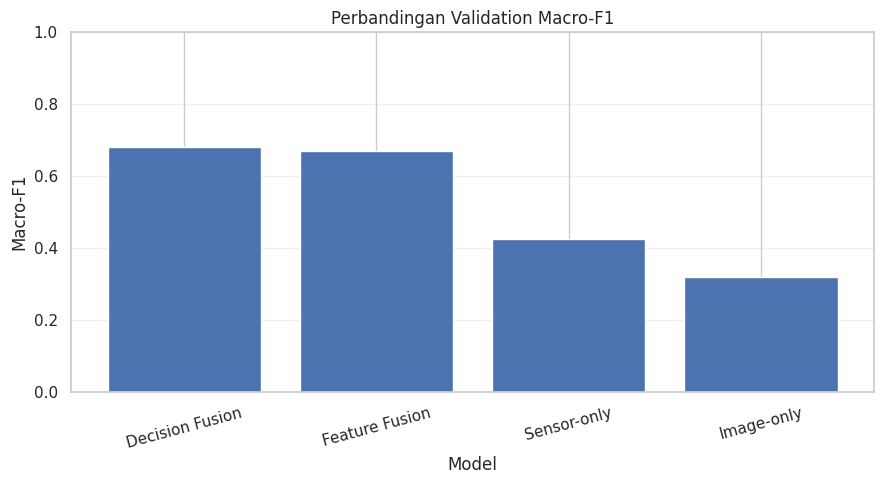

In [56]:

# 49. Visualisasi Perbandingan Model

plt.figure(figsize=(9, 5))

plt.bar(
    comparison_df["Model"],
    comparison_df["Validation Macro-F1"]
)

plt.title("Perbandingan Validation Macro-F1")
plt.ylabel("Macro-F1")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [57]:

# 50. Evaluasi Decision Fusion

criterion = nn.CrossEntropyLoss(weight=class_weights)

_, decision_metrics, y_true, y_pred = evaluate_model(
    decision_model,
    val_loader,
    criterion,
    model_type="multimodal"
)

print("Validation Metrics:")
for metric, value in decision_metrics.items():
    print(f"{metric}: {value:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        labels=np.arange(len(class_names)),
        target_names=class_names,
        zero_division=0
    )
)


Validation Metrics:
accuracy: 0.7129
precision: 0.6983
recall: 0.6770
macro_f1: 0.6821

Classification Report:
              precision    recall  f1-score   support

   gelembung       0.62      0.78      0.69       686
       gores       0.32      0.27      0.29      1124
 kontaminasi       0.81      0.72      0.76       471
  las_dingin       0.97      0.91      0.94       865
        noda       0.81      0.57      0.67       955
      normal       0.76      0.80      0.78      4778
       retak       0.60      0.70      0.65       721

    accuracy                           0.71      9600
   macro avg       0.70      0.68      0.68      9600
weighted avg       0.71      0.71      0.71      9600



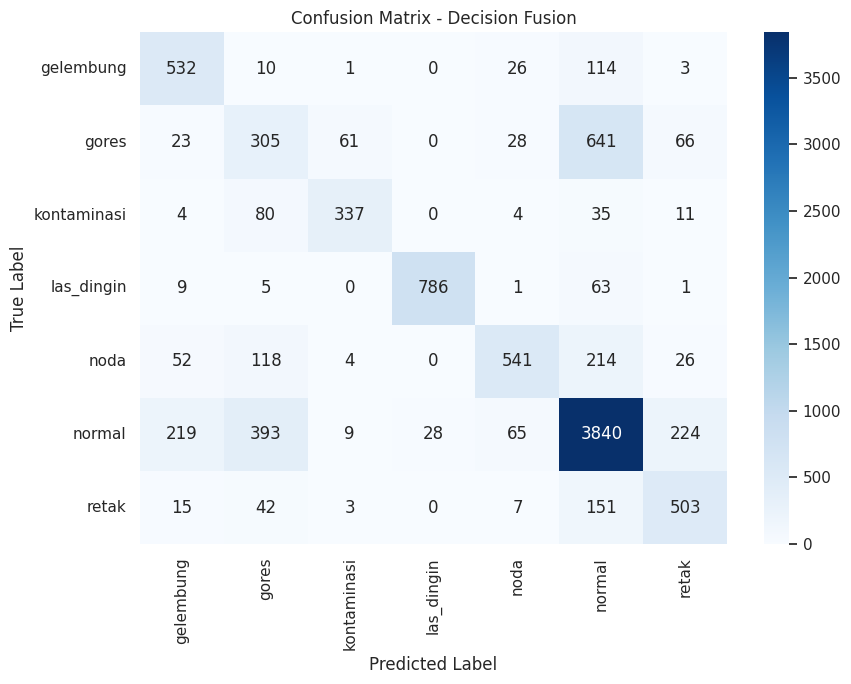

In [58]:

# 51. Confusion Matrix

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(len(class_names))
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Confusion Matrix - Decision Fusion")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()


NOTES :

Berdasarkan evaluasi pada data validation, model Decision-level Fusion memperoleh accuracy sebesar 71,29% dan Macro-F1 sebesar 0,6821. Kelas las_dingin menghasilkan performa klasifikasi terbaik dengan F1-score 0,94, sedangkan kelas gores memiliki F1-score terendah sebesar 0,29. Kesalahan klasifikasi paling banyak terjadi ketika sampel gores diprediksi sebagai normal. Hasil ini menunjukkan bahwa model multimodal mampu mengklasifikasikan sebagian besar kelas dengan baik, tetapi masih mengalami kesulitan dalam membedakan beberapa kelas yang memiliki karakteristik serupa.



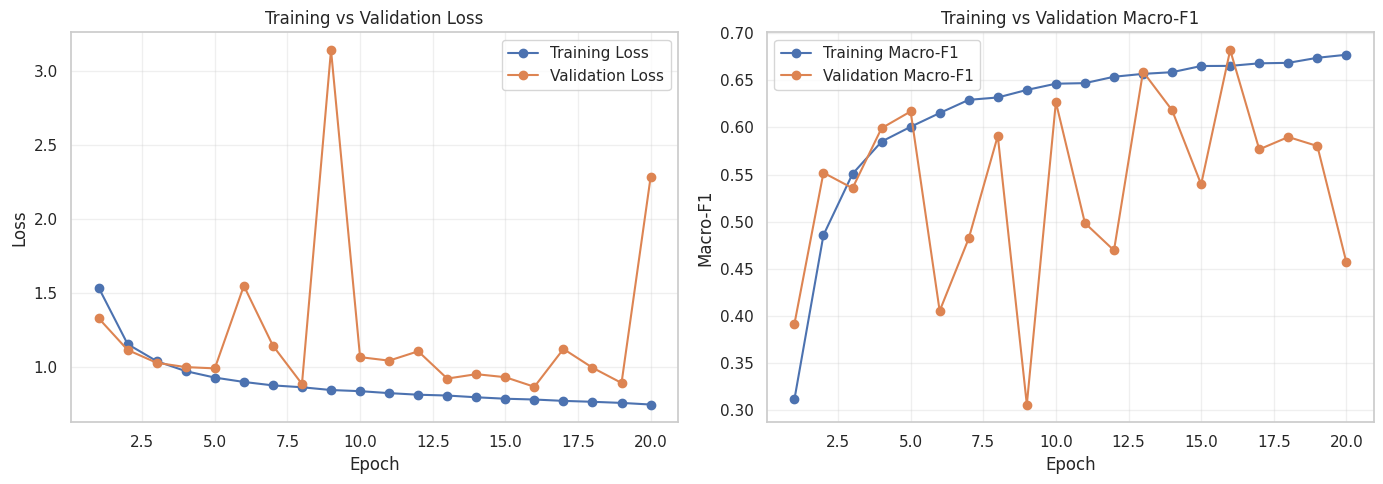

In [59]:

# 52. Visualisasi Learning Curves - Decision Fusion

epochs_range = range(1, len(decision_history["train_loss"]) + 1)

plt.figure(figsize=(14, 5))

# Loss Curve
plt.subplot(1, 2, 1)
plt.plot(epochs_range, decision_history["train_loss"],
         marker="o", label="Training Loss")
plt.plot(epochs_range, decision_history["val_loss"],
         marker="o", label="Validation Loss")

plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)

# Macro-F1 Curve
plt.subplot(1, 2, 2)
plt.plot(epochs_range, decision_history["train_f1"],
         marker="o", label="Training Macro-F1")
plt.plot(epochs_range, decision_history["val_f1"],
         marker="o", label="Validation Macro-F1")

plt.title("Training vs Validation Macro-F1")
plt.xlabel("Epoch")
plt.ylabel("Macro-F1")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


NOTES :

Berdasarkan learning curves, model Decision Fusion menunjukkan peningkatan performa pada data training yang ditandai dengan penurunan training loss dan peningkatan training Macro-F1. Namun, performa validation mengalami fluktuasi selama proses training. Validation Macro-F1 terbaik sebesar 0,6821 diperoleh pada epoch ke-16. Perbedaan pola antara training dan validation menunjukkan adanya indikasi ketidakstabilan generalisasi model, sehingga diperlukan pengujian robustness lebih lanjut.

In [60]:

# 53. Menyimpan Checkpoint Model Terbaik

torch.save(
    decision_model.state_dict(),
    "decision_fusion_best.pth"
)

print("Model Decision Fusion berhasil disimpan.")


Model Decision Fusion berhasil disimpan.


In [61]:

# 54. Simulasi Label Noise

def add_label_noise(labels, noise_rate, num_classes, seed=42):
    noisy_labels = labels.copy()

    rng = np.random.default_rng(seed)
    n_samples = len(labels)
    n_noisy = int(noise_rate * n_samples)

    noisy_indices = rng.choice(
        n_samples,
        size=n_noisy,
        replace=False
    )

    for idx in noisy_indices:
        possible_labels = [
            c for c in range(num_classes)
            if c != labels[idx]
        ]

        noisy_labels[idx] = rng.choice(possible_labels)

    return noisy_labels


y_train_10 = add_label_noise(
    y_train, 0.10, len(class_names), seed=42
)

y_train_20 = add_label_noise(
    y_train, 0.20, len(class_names), seed=42
)

print("Jumlah data training:", len(y_train))
print("Noise 10%:", np.sum(y_train != y_train_10))
print("Noise 20%:", np.sum(y_train != y_train_20))


Jumlah data training: 38400
Noise 10%: 3840
Noise 20%: 7680


In [62]:

# 55. Membuat DataLoader Label Noise

train_dataset_10 = ProductDefectDataset(
    X_image_train,
    X_sensor_train,
    y_train_10
)

train_dataset_20 = ProductDefectDataset(
    X_image_train,
    X_sensor_train,
    y_train_20
)

train_loader_10 = DataLoader(
    train_dataset_10,
    batch_size=64,
    shuffle=True
)

train_loader_20 = DataLoader(
    train_dataset_20,
    batch_size=64,
    shuffle=True
)

print("DataLoader noise 10%:", len(train_loader_10))
print("DataLoader noise 20%:", len(train_loader_20))


DataLoader noise 10%: 600
DataLoader noise 20%: 600


##Training Decision Fusion dengan Noise 10%


In [63]:

# 56. Training Decision Fusion - Noise 10%

decision_noise_10 = DecisionFusionModel().to(device)

decision_noise_10, history_noise_10 = train_model(
    decision_noise_10,
    train_loader_10,
    val_loader,
    model_type="multimodal",
    epochs=20,
    patience=5,
    lr=0.0003
)


Epoch [1/20] Train Loss: 1.6965 | Val Loss: 1.3720 | Val Macro-F1: 0.3601
Epoch [2/20] Train Loss: 1.4660 | Val Loss: 1.2479 | Val Macro-F1: 0.3420
Epoch [3/20] Train Loss: 1.3964 | Val Loss: 1.6270 | Val Macro-F1: 0.3292
Epoch [4/20] Train Loss: 1.3496 | Val Loss: 1.1297 | Val Macro-F1: 0.5190
Epoch [5/20] Train Loss: 1.3157 | Val Loss: 1.0879 | Val Macro-F1: 0.5650
Epoch [6/20] Train Loss: 1.2899 | Val Loss: 1.0587 | Val Macro-F1: 0.4666
Epoch [7/20] Train Loss: 1.2705 | Val Loss: 1.0448 | Val Macro-F1: 0.6090
Epoch [8/20] Train Loss: 1.2571 | Val Loss: 1.1305 | Val Macro-F1: 0.5888
Epoch [9/20] Train Loss: 1.2457 | Val Loss: 0.9952 | Val Macro-F1: 0.5270
Epoch [10/20] Train Loss: 1.2392 | Val Loss: 1.1246 | Val Macro-F1: 0.4684
Epoch [11/20] Train Loss: 1.2326 | Val Loss: 1.0497 | Val Macro-F1: 0.4821
Epoch [12/20] Train Loss: 1.2231 | Val Loss: 1.0193 | Val Macro-F1: 0.5146
Early stopping aktif.
Best Validation Macro-F1: 0.6090


##Training Model dengan Label Noise 20%

In [64]:

# 57. Training Decision Fusion - Noise 20%

decision_noise_20 = DecisionFusionModel().to(device)

decision_noise_20, history_noise_20 = train_model(
    decision_noise_20,
    train_loader_20,
    val_loader,
    model_type="multimodal",
    epochs=20,
    patience=5,
    lr=0.0003
)


Epoch [1/20] Train Loss: 1.7804 | Val Loss: 1.4649 | Val Macro-F1: 0.3323
Epoch [2/20] Train Loss: 1.6489 | Val Loss: 1.3323 | Val Macro-F1: 0.3239
Epoch [3/20] Train Loss: 1.5964 | Val Loss: 1.2707 | Val Macro-F1: 0.4865
Epoch [4/20] Train Loss: 1.5575 | Val Loss: 1.1852 | Val Macro-F1: 0.5483
Epoch [5/20] Train Loss: 1.5304 | Val Loss: 1.2217 | Val Macro-F1: 0.4178
Epoch [6/20] Train Loss: 1.5098 | Val Loss: 1.1712 | Val Macro-F1: 0.4642
Epoch [7/20] Train Loss: 1.4947 | Val Loss: 1.1630 | Val Macro-F1: 0.5040
Epoch [8/20] Train Loss: 1.4858 | Val Loss: 1.2184 | Val Macro-F1: 0.4293
Epoch [9/20] Train Loss: 1.4758 | Val Loss: 1.1595 | Val Macro-F1: 0.4439
Early stopping aktif.
Best Validation Macro-F1: 0.5483


In [65]:

# 58. Perbandingan Label Noise

noise_results = pd.DataFrame({
    "Kondisi": [
        "Tanpa Noise",
        "Noise 10%",
        "Noise 20%"
    ],
    "Validation Macro-F1": [
        max(decision_history["val_f1"]),
        max(history_noise_10["val_f1"]),
        max(history_noise_20["val_f1"])
    ]
})

display(noise_results)


,Kondisi,Validation Macro-F1
0,Tanpa Noise,0.682053
1,Noise 10%,0.608995
2,Noise 20%,0.548334


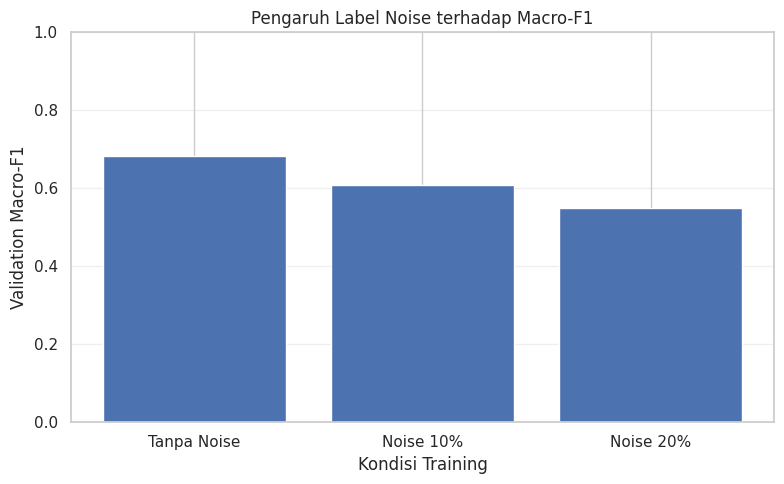

In [66]:

# 59. Visualisasi Ketahanan terhadap Label Noise

plt.figure(figsize=(8, 5))

plt.bar(
    noise_results["Kondisi"],
    noise_results["Validation Macro-F1"]
)

plt.title("Pengaruh Label Noise terhadap Macro-F1")
plt.xlabel("Kondisi Training")
plt.ylabel("Validation Macro-F1")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


NOTE

Pengujian label noise dilakukan dengan mengubah 10% dan 20% label pada data training secara acak. Hasil eksperimen menunjukkan bahwa model Decision Fusion memperoleh Macro-F1 sebesar 0,6821 pada kondisi tanpa noise, 0,6090 pada noise 10%, dan 0,5483 pada noise 20%. Hasil tersebut menunjukkan bahwa peningkatan tingkat kesalahan label menyebabkan penurunan performa klasifikasi. Meskipun demikian, model masih mampu mempertahankan performa Macro-F1 di atas 0,54 pada kondisi noise 20%.

In [67]:

# 60. Distribusi Lini Produksi

print("Distribusi Lini pada Training:")
print(train_meta_split["lini"].value_counts())

print("\nDistribusi Lini pada Validation:")
print(val_meta_split["lini"].value_counts())

print("\nDistribusi Kelas berdasarkan Lini Training:")
display(
    pd.crosstab(
        train_meta_split["lini"],
        train_meta_split["kelas"]
    )
)


Distribusi Lini pada Training:
lini
A    28811
B     9589
Name: count, dtype: int64

Distribusi Lini pada Validation:
lini
A    7153
B    2447
Name: count, dtype: int64

Distribusi Kelas berdasarkan Lini Training:


kelas,gelembung,gores,kontaminasi,las_dingin,noda,normal,retak
lini,,,,,,,
A,2052,3380,1430,2601,2862,14332,2154
B,692,1119,456,857,956,4778,731


In [68]:

# 61. Memisahkan Data berdasarkan Lini Produksi

# Mask untuk data training
mask_train_A = (
    train_meta_split["lini"].to_numpy() == "A"
)

# Mask untuk data validation
mask_val_B = (
    val_meta_split["lini"].to_numpy() == "B"
)

# Data training hanya Lini A
X_image_train_A = X_image_train[mask_train_A]
X_sensor_train_A = X_sensor_train[mask_train_A]
y_train_A = np.asarray(y_train)[mask_train_A]

# Data validation hanya Lini B
X_image_val_B = X_image_val[mask_val_B]
X_sensor_val_B = X_sensor_val[mask_val_B]
y_val_B = np.asarray(y_val)[mask_val_B]

print("Training Lini A:", len(y_train_A))
print("Validation Lini B:", len(y_val_B))

print("\nDistribusi kelas Training A:")
print(pd.Series(y_train_A).value_counts().sort_index())

print("\nDistribusi kelas Validation B:")
print(pd.Series(y_val_B).value_counts().sort_index())


Training Lini A: 28811
Validation Lini B: 2447

Distribusi kelas Training A:
0     2052
1     3380
2     1430
3     2601
4     2862
5    14332
6     2154
Name: count, dtype: int64

Distribusi kelas Validation B:
0     161
1     273
2     124
3     216
4     249
5    1248
6     176
Name: count, dtype: int64


In [69]:

# 62. DataLoader Domain Shift

domain_train_dataset = ProductDefectDataset(
    X_image_train_A,
    X_sensor_train_A,
    y_train_A
)

domain_val_dataset = ProductDefectDataset(
    X_image_val_B,
    X_sensor_val_B,
    y_val_B
)

domain_train_loader = DataLoader(
    domain_train_dataset,
    batch_size=64,
    shuffle=True
)

domain_val_loader = DataLoader(
    domain_val_dataset,
    batch_size=64,
    shuffle=False
)

print("Jumlah batch training:", len(domain_train_loader))
print("Jumlah batch validation:", len(domain_val_loader))


Jumlah batch training: 451
Jumlah batch validation: 39


In [70]:

# 63. Class Weight Domain Shift

domain_class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(class_names)),
    y=y_train_A
)

domain_class_weights = torch.tensor(
    domain_class_weights,
    dtype=torch.float32
).to(device)

print("Domain Class Weights:")
for i, weight in enumerate(domain_class_weights):
    print(f"{idx_to_class[i]}: {weight.item():.4f}")


Domain Class Weights:
gelembung: 2.0058
gores: 1.2177
kontaminasi: 2.8782
las_dingin: 1.5824
noda: 1.4381
normal: 0.2872
retak: 1.9108


In [71]:
# 64. Training Domain Shift

original_class_weights = class_weights.clone()
class_weights = domain_class_weights

domain_model = DecisionFusionModel().to(device)

domain_model, domain_history = train_model(
    domain_model,
    domain_train_loader,
    domain_val_loader,
    model_type="multimodal",
    epochs=20,
    patience=5,
    lr=0.0003
)

# Mengembalikan class weights sebelumnya
class_weights = original_class_weights

Epoch [1/20] Train Loss: 1.4425 | Val Loss: 11.8358 | Val Macro-F1: 0.0612
Epoch [2/20] Train Loss: 1.0568 | Val Loss: 9.0850 | Val Macro-F1: 0.0847
Epoch [3/20] Train Loss: 0.9477 | Val Loss: 15.1720 | Val Macro-F1: 0.0595
Epoch [4/20] Train Loss: 0.8819 | Val Loss: 13.9283 | Val Macro-F1: 0.0806
Epoch [5/20] Train Loss: 0.8386 | Val Loss: 8.1481 | Val Macro-F1: 0.1037
Epoch [6/20] Train Loss: 0.8080 | Val Loss: 11.5130 | Val Macro-F1: 0.0588
Epoch [7/20] Train Loss: 0.7858 | Val Loss: 8.5105 | Val Macro-F1: 0.1313
Epoch [8/20] Train Loss: 0.7685 | Val Loss: 10.0332 | Val Macro-F1: 0.1672
Epoch [9/20] Train Loss: 0.7611 | Val Loss: 7.6348 | Val Macro-F1: 0.1309
Epoch [10/20] Train Loss: 0.7432 | Val Loss: 8.0411 | Val Macro-F1: 0.1970
Epoch [11/20] Train Loss: 0.7310 | Val Loss: 12.2038 | Val Macro-F1: 0.1261
Epoch [12/20] Train Loss: 0.7278 | Val Loss: 10.9980 | Val Macro-F1: 0.1294
Epoch [13/20] Train Loss: 0.7132 | Val Loss: 19.1936 | Val Macro-F1: 0.0794
Epoch [14/20] Train Loss: 

In [72]:

# 65. Evaluasi Domain Shift

criterion = nn.CrossEntropyLoss(
    weight=domain_class_weights
)

_, domain_metrics, domain_y_true, domain_y_pred = evaluate_model(
    domain_model,
    domain_val_loader,
    criterion,
    model_type="multimodal"
)

print("Domain Shift Evaluation - A to B")

for metric, value in domain_metrics.items():
    print(f"{metric}: {value:.4f}")


Domain Shift Evaluation - A to B
accuracy: 0.1614
precision: 0.4961
recall: 0.2589
macro_f1: 0.1970


In [73]:

# 66. Evaluasi Model Normal pada Lini B

criterion = nn.CrossEntropyLoss(
    weight=original_class_weights
)

_, normal_on_B_metrics, _, _ = evaluate_model(
    decision_model,
    domain_val_loader,
    criterion,
    model_type="multimodal"
)

print("Model Training Lini A + B, Evaluation Lini B")

for metric, value in normal_on_B_metrics.items():
    print(f"{metric}: {value:.4f}")


Model Training Lini A + B, Evaluation Lini B
accuracy: 0.5885
precision: 0.5883
recall: 0.6048
macro_f1: 0.5869


,Model,Validation Macro-F1
0,Training Lini A + B,0.586943
1,Training Lini A,0.196984


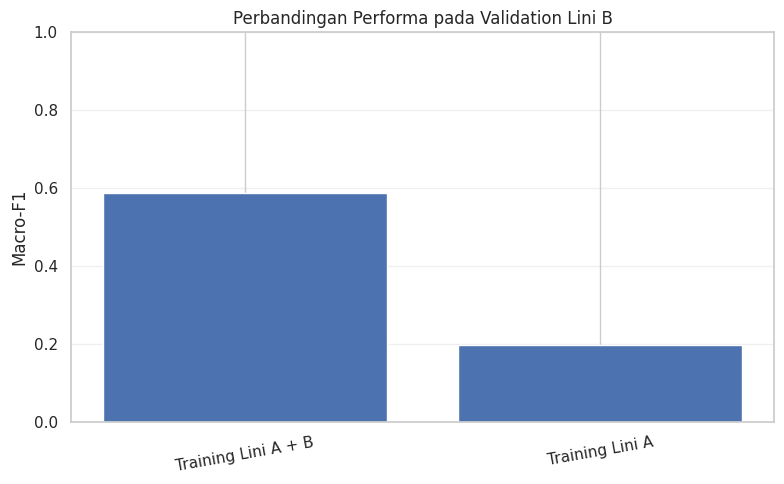

In [74]:

# 67. Perbandingan Domain Shift

domain_comparison = pd.DataFrame({
    "Model": [
        "Training Lini A + B",
        "Training Lini A"
    ],
    "Validation Macro-F1": [
        normal_on_B_metrics["macro_f1"],
        domain_metrics["macro_f1"]
    ]
})

display(domain_comparison)

plt.figure(figsize=(8, 5))

plt.bar(
    domain_comparison["Model"],
    domain_comparison["Validation Macro-F1"]
)

plt.title("Perbandingan Performa pada Validation Lini B")
plt.ylabel("Macro-F1")
plt.ylim(0, 1)
plt.xticks(rotation=10)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


NOTES:

Pengujian domain shift dilakukan dengan membandingkan model yang dilatih menggunakan data Lini A dan B dengan model yang hanya dilatih menggunakan Lini A. Kedua model dievaluasi pada data validation Lini B yang sama. Model yang dilatih menggunakan kedua lini memperoleh Macro-F1 sebesar 0,5869, sedangkan model yang hanya dilatih menggunakan Lini A memperoleh 0,1970. Hasil ini menunjukkan bahwa perbedaan lini produksi memberikan pengaruh signifikan terhadap kemampuan generalisasi model.

In [75]:

# 68. Fungsi Evaluasi Missing Modality

def evaluate_missing_modality(
    model,
    loader,
    missing=None
):
    model.eval()

    all_preds = []
    all_labels = []

    with torch.no_grad():
        for images, sensors, labels in loader:

            images = images.to(device)
            sensors = sensors.to(device)

            if missing == "image":
                images = image_mean_tensor.expand_as(images)

            elif missing == "sensor":
                sensors = torch.zeros_like(sensors)

            outputs = model(images, sensors)

            preds = outputs.argmax(dim=1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.numpy())

    score = f1_score(
        all_labels,
        all_preds,
        average="macro",
        zero_division=0
    )

    return score


In [77]:

# 69. Membuat Rata-rata Gambar Training

image_mean = X_image_train.mean(
    axis=0,
    keepdims=True
)

image_mean_tensor = torch.tensor(
    image_mean,
    dtype=torch.float32
).unsqueeze(1).to(device)

print("Image mean shape:", image_mean_tensor.shape)


Image mean shape: torch.Size([1, 1, 64, 64])


In [78]:

# 70. Eksperimen Missing Modality

complete_score = evaluate_missing_modality(
    decision_model,
    val_loader,
    missing=None
)

missing_image_score = evaluate_missing_modality(
    decision_model,
    val_loader,
    missing="image"
)

missing_sensor_score = evaluate_missing_modality(
    decision_model,
    val_loader,
    missing="sensor"
)

missing_results = pd.DataFrame({
    "Kondisi": [
        "Complete Modality",
        "Missing Image",
        "Missing Sensor"
    ],
    "Validation Macro-F1": [
        complete_score,
        missing_image_score,
        missing_sensor_score
    ]
})

display(missing_results)


,Kondisi,Validation Macro-F1
0,Complete Modality,0.682053
1,Missing Image,0.350670
2,Missing Sensor,0.301247


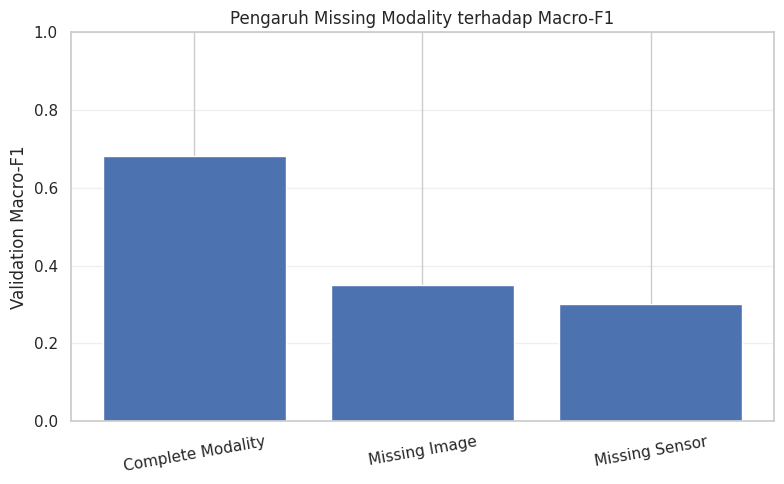

In [79]:

# 71. Visualisasi Missing Modality

plt.figure(figsize=(8, 5))

plt.bar(
    missing_results["Kondisi"],
    missing_results["Validation Macro-F1"]
)

plt.title("Pengaruh Missing Modality terhadap Macro-F1")
plt.ylabel("Validation Macro-F1")
plt.ylim(0, 1)
plt.xticks(rotation=10)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


NOTES :

Pengujian missing modality dilakukan untuk mengetahui pengaruh hilangnya salah satu sumber informasi terhadap performa model Decision Fusion. Pada kondisi lengkap, model memperoleh Macro-F1 sebesar 0,6821. Ketika gambar dihilangkan, Macro-F1 turun menjadi 0,3507, sedangkan ketika sensor dihilangkan, Macro-F1 turun menjadi 0,3012. Hasil ini menunjukkan bahwa kedua modalitas memberikan kontribusi terhadap performa klasifikasi dan penggunaan keduanya secara bersamaan menghasilkan performa terbaik.

In [80]:

# 72. Mengacak Label Training

rng = np.random.default_rng(123)

y_train_shuffled = rng.permutation(
    np.asarray(y_train)
)

print("Label asli (10 pertama):", np.asarray(y_train)[:10])
print("Label acak (10 pertama):", y_train_shuffled[:10])

print(
    "Jumlah label yang berubah:",
    np.sum(np.asarray(y_train) != y_train_shuffled)
)


Label asli (10 pertama): [4 5 1 1 5 5 5 1 1 1]
Label acak (10 pertama): [5 4 0 5 6 6 0 6 5 4]
Jumlah label yang berubah: 27052


In [81]:

# 73. DataLoader Sanity Check

sanity_dataset = ProductDefectDataset(
    X_image_train,
    X_sensor_train,
    y_train_shuffled
)

sanity_loader = DataLoader(
    sanity_dataset,
    batch_size=64,
    shuffle=True
)

print("Jumlah data:", len(sanity_dataset))
print("Jumlah batch:", len(sanity_loader))


Jumlah data: 38400
Jumlah batch: 600


In [82]:

# 74. Training Sanity Check

sanity_model = DecisionFusionModel().to(device)

sanity_model, sanity_history = train_model(
    sanity_model,
    sanity_loader,
    val_loader,
    model_type="multimodal",
    epochs=10,
    patience=3,
    lr=0.0003
)


Epoch [1/10] Train Loss: 1.9516 | Val Loss: 1.9468 | Val Macro-F1: 0.0258
Epoch [2/10] Train Loss: 1.9476 | Val Loss: 1.9460 | Val Macro-F1: 0.1045
Epoch [3/10] Train Loss: 1.9473 | Val Loss: 1.9445 | Val Macro-F1: 0.0335
Epoch [4/10] Train Loss: 1.9466 | Val Loss: 1.9406 | Val Macro-F1: 0.1372
Epoch [5/10] Train Loss: 1.9461 | Val Loss: 1.9476 | Val Macro-F1: 0.0526
Epoch [6/10] Train Loss: 1.9454 | Val Loss: 1.9462 | Val Macro-F1: 0.1271
Epoch [7/10] Train Loss: 1.9454 | Val Loss: 1.9448 | Val Macro-F1: 0.0785
Early stopping aktif.
Best Validation Macro-F1: 0.1372


In [83]:

# 75. Evaluasi Sanity Check

criterion = nn.CrossEntropyLoss(
    weight=original_class_weights
)

_, sanity_metrics, _, _ = evaluate_model(
    sanity_model,
    val_loader,
    criterion,
    model_type="multimodal"
)

print("Sanity Check Results:")

for metric, value in sanity_metrics.items():
    print(f"{metric}: {value:.4f}")

print("\nBaseline Macro-F1:", 0.6821)
print("Shuffled-label Macro-F1:", sanity_metrics["macro_f1"])


Sanity Check Results:
accuracy: 0.3155
precision: 0.1883
recall: 0.1755
macro_f1: 0.1372

Baseline Macro-F1: 0.6821
Shuffled-label Macro-F1: 0.13715106447638395


Notes :

Sanity check dilakukan dengan mengacak seluruh label pada data training, sementara label validation tetap dipertahankan. Hasil menunjukkan penurunan Validation Macro-F1 dari 0,6821 menjadi 0,1372. Hal ini menunjukkan bahwa performa model pada eksperimen normal bukan sekadar hasil prediksi acak, melainkan berasal dari pembelajaran hubungan antara data input dan label kelas.

In [84]:

# 76. Mengatur Random Seed

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

print("Random seed function siap.")


Random seed function siap.


In [85]:

# 77. Eksperimen 3 Random Seeds - Decision Fusion

seeds = [42, 123, 2026]

seed_results = []
seed_models = {}
seed_histories = {}

for seed in seeds:
    print(f"\n========== SEED {seed} ==========")

    set_seed(seed)

    model = DecisionFusionModel().to(device)

    model, history = train_model(
        model,
        train_loader,
        val_loader,
        model_type="multimodal",
        epochs=20,
        patience=5,
        lr=0.0003
    )

    best_f1 = max(history["val_f1"])

    seed_results.append({
        "Seed": seed,
        "Best Validation Macro-F1": best_f1
    })

    seed_models[seed] = model
    seed_histories[seed] = history

seed_df = pd.DataFrame(seed_results)

display(seed_df)



========== SEED 42 ==========
Epoch [1/20] Train Loss: 1.5363 | Val Loss: 1.3025 | Val Macro-F1: 0.3308
Epoch [2/20] Train Loss: 1.1830 | Val Loss: 1.1302 | Val Macro-F1: 0.5076
Epoch [3/20] Train Loss: 1.0799 | Val Loss: 1.1648 | Val Macro-F1: 0.5597
Epoch [4/20] Train Loss: 1.0167 | Val Loss: 1.0608 | Val Macro-F1: 0.4824
Epoch [5/20] Train Loss: 0.9638 | Val Loss: 0.9920 | Val Macro-F1: 0.5901
Epoch [6/20] Train Loss: 0.9259 | Val Loss: 0.9500 | Val Macro-F1: 0.5977
Epoch [7/20] Train Loss: 0.9043 | Val Loss: 0.9213 | Val Macro-F1: 0.6010
Epoch [8/20] Train Loss: 0.8795 | Val Loss: 1.0889 | Val Macro-F1: 0.5506
Epoch [9/20] Train Loss: 0.8641 | Val Loss: 0.9124 | Val Macro-F1: 0.5665
Epoch [10/20] Train Loss: 0.8518 | Val Loss: 1.0419 | Val Macro-F1: 0.5130
Epoch [11/20] Train Loss: 0.8415 | Val Loss: 0.8882 | Val Macro-F1: 0.6403
Epoch [12/20] Train Loss: 0.8305 | Val Loss: 0.8606 | Val Macro-F1: 0.6446
Epoch [13/20] Train Loss: 0.8146 | Val Loss: 0.8617 | Val Macro-F1: 0.6634
Epo

,Seed,Best Validation Macro-F1
0,42,0.663737
1,123,0.615468
2,2026,0.643443


In [86]:

# 78. Ringkasan Hasil 3 Seeds

mean_f1 = seed_df["Best Validation Macro-F1"].mean()
std_f1 = seed_df["Best Validation Macro-F1"].std()

print(f"Mean Macro-F1: {mean_f1:.4f}")
print(f"Std Macro-F1 : {std_f1:.4f}")
print(f"Mean ± Std   : {mean_f1:.4f} ± {std_f1:.4f}")


Mean Macro-F1: 0.6409
Std Macro-F1 : 0.0242
Mean ± Std   : 0.6409 ± 0.0242


NOTES :

Pengujian reproducibility dilakukan menggunakan tiga random seed, yaitu 42, 123, dan 2026. Model Decision Fusion memperoleh Validation Macro-F1 masing-masing sebesar 0,6637, 0,6155, dan 0,6434. Rata-rata performa yang diperoleh adalah 0,6409 dengan standar deviasi 0,0242. Hasil ini menunjukkan bahwa performa model relatif konsisten terhadap variasi random seed, meskipun masih terdapat perbedaan hasil antarpercobaan.

In [87]:

# 79. Multiple Seeds - Image-only

image_seed_results = []
image_seed_models = {}

for seed in seeds:
    print(f"\n========== IMAGE-ONLY SEED {seed} ==========")

    set_seed(seed)

    model = ImageOnlyModel().to(device)

    model, history = train_model(
        model,
        train_loader,
        val_loader,
        model_type="image",
        epochs=20,
        patience=5,
        lr=0.0003
    )

    best_f1 = max(history["val_f1"])

    image_seed_results.append({
        "Seed": seed,
        "Best Validation Macro-F1": best_f1
    })

    image_seed_models[seed] = model

image_seed_df = pd.DataFrame(image_seed_results)
display(image_seed_df)



========== IMAGE-ONLY SEED 42 ==========
Epoch [1/20] Train Loss: 1.9147 | Val Loss: 1.9166 | Val Macro-F1: 0.0570
Epoch [2/20] Train Loss: 1.8070 | Val Loss: 1.8161 | Val Macro-F1: 0.2289
Epoch [3/20] Train Loss: 1.7332 | Val Loss: 1.6978 | Val Macro-F1: 0.2727
Epoch [4/20] Train Loss: 1.6847 | Val Loss: 1.8240 | Val Macro-F1: 0.1222
Epoch [5/20] Train Loss: 1.6361 | Val Loss: 1.8237 | Val Macro-F1: 0.2460
Epoch [6/20] Train Loss: 1.6021 | Val Loss: 1.5896 | Val Macro-F1: 0.3272
Epoch [7/20] Train Loss: 1.5685 | Val Loss: 1.7829 | Val Macro-F1: 0.1968
Epoch [8/20] Train Loss: 1.5565 | Val Loss: 2.0227 | Val Macro-F1: 0.1184
Epoch [9/20] Train Loss: 1.5374 | Val Loss: 1.8113 | Val Macro-F1: 0.2712
Epoch [10/20] Train Loss: 1.5283 | Val Loss: 1.5765 | Val Macro-F1: 0.2999
Epoch [11/20] Train Loss: 1.5177 | Val Loss: 1.7866 | Val Macro-F1: 0.2666
Early stopping aktif.
Best Validation Macro-F1: 0.3272

========== IMAGE-ONLY SEED 123 ==========
Epoch [1/20] Train Loss: 1.9040 | Val Loss: 

,Seed,Best Validation Macro-F1
0,42,0.327244
1,123,0.315917
2,2026,0.293853


In [88]:

# 80. Multiple Seeds - Sensor-only

sensor_seed_results = []
sensor_seed_models = {}

for seed in seeds:
    print(f"\n========== SENSOR-ONLY SEED {seed} ==========")

    set_seed(seed)

    model = SensorOnlyModel().to(device)

    model, history = train_model(
        model,
        train_loader,
        val_loader,
        model_type="sensor",
        epochs=20,
        patience=5,
        lr=0.0003
    )

    best_f1 = max(history["val_f1"])

    sensor_seed_results.append({
        "Seed": seed,
        "Best Validation Macro-F1": best_f1
    })

    sensor_seed_models[seed] = model

sensor_seed_df = pd.DataFrame(sensor_seed_results)
display(sensor_seed_df)



========== SENSOR-ONLY SEED 42 ==========
Epoch [1/20] Train Loss: 1.5734 | Val Loss: 1.3413 | Val Macro-F1: 0.3394
Epoch [2/20] Train Loss: 1.2945 | Val Loss: 1.2560 | Val Macro-F1: 0.3582
Epoch [3/20] Train Loss: 1.2462 | Val Loss: 1.2192 | Val Macro-F1: 0.3757
Epoch [4/20] Train Loss: 1.2168 | Val Loss: 1.1997 | Val Macro-F1: 0.4400
Epoch [5/20] Train Loss: 1.2061 | Val Loss: 1.1992 | Val Macro-F1: 0.3822
Epoch [6/20] Train Loss: 1.1936 | Val Loss: 1.2324 | Val Macro-F1: 0.3229
Epoch [7/20] Train Loss: 1.1844 | Val Loss: 1.1875 | Val Macro-F1: 0.3755
Epoch [8/20] Train Loss: 1.1765 | Val Loss: 1.1884 | Val Macro-F1: 0.3995
Epoch [9/20] Train Loss: 1.1740 | Val Loss: 1.1811 | Val Macro-F1: 0.3851
Early stopping aktif.
Best Validation Macro-F1: 0.4400

========== SENSOR-ONLY SEED 123 ==========
Epoch [1/20] Train Loss: 1.5805 | Val Loss: 1.3416 | Val Macro-F1: 0.3259
Epoch [2/20] Train Loss: 1.2871 | Val Loss: 1.2375 | Val Macro-F1: 0.4256
Epoch [3/20] Train Loss: 1.2318 | Val Loss: 

,Seed,Best Validation Macro-F1
0,42,0.440002
1,123,0.433232
2,2026,0.428421


In [89]:

# 81. Multiple Seeds - Feature Fusion

feature_seed_results = []
feature_seed_models = {}

for seed in seeds:
    print(f"\n========== FEATURE FUSION SEED {seed} ==========")

    set_seed(seed)

    model = FeatureFusionModel().to(device)

    model, history = train_model(
        model,
        train_loader,
        val_loader,
        model_type="multimodal",
        epochs=20,
        patience=5,
        lr=0.0003
    )

    best_f1 = max(history["val_f1"])

    feature_seed_results.append({
        "Seed": seed,
        "Best Validation Macro-F1": best_f1
    })

    feature_seed_models[seed] = model

feature_seed_df = pd.DataFrame(feature_seed_results)
display(feature_seed_df)



========== FEATURE FUSION SEED 42 ==========
Epoch [1/20] Train Loss: 1.5080 | Val Loss: 1.2788 | Val Macro-F1: 0.4250
Epoch [2/20] Train Loss: 1.1465 | Val Loss: 1.1899 | Val Macro-F1: 0.3969
Epoch [3/20] Train Loss: 1.0635 | Val Loss: 1.1171 | Val Macro-F1: 0.5643
Epoch [4/20] Train Loss: 1.0043 | Val Loss: 0.9982 | Val Macro-F1: 0.5972
Epoch [5/20] Train Loss: 0.9439 | Val Loss: 0.8819 | Val Macro-F1: 0.6051
Epoch [6/20] Train Loss: 0.8996 | Val Loss: 1.0477 | Val Macro-F1: 0.6029
Epoch [7/20] Train Loss: 0.8686 | Val Loss: 1.1283 | Val Macro-F1: 0.5277
Epoch [8/20] Train Loss: 0.8525 | Val Loss: 0.8430 | Val Macro-F1: 0.6488
Epoch [9/20] Train Loss: 0.8311 | Val Loss: 0.8505 | Val Macro-F1: 0.6029
Epoch [10/20] Train Loss: 0.8186 | Val Loss: 1.0393 | Val Macro-F1: 0.6344
Epoch [11/20] Train Loss: 0.8130 | Val Loss: 0.9108 | Val Macro-F1: 0.6359
Epoch [12/20] Train Loss: 0.7937 | Val Loss: 0.8480 | Val Macro-F1: 0.6244
Epoch [13/20] Train Loss: 0.7906 | Val Loss: 1.2175 | Val Macro

,Seed,Best Validation Macro-F1
0,42,0.648771
1,123,0.673095
2,2026,0.655422


In [90]:

# 82. Rekapitulasi Final Performa Model

all_seed_results = {
    "Image-only": image_seed_df,
    "Sensor-only": sensor_seed_df,
    "Feature Fusion": feature_seed_df,
    "Decision Fusion": seed_df
}

summary_results = []

for model_name, df in all_seed_results.items():
    scores = df["Best Validation Macro-F1"]

    summary_results.append({
        "Model": model_name,
        "Mean Macro-F1": scores.mean(),
        "Std Macro-F1": scores.std(ddof=1)
    })

final_comparison_df = pd.DataFrame(summary_results)

final_comparison_df = final_comparison_df.sort_values(
    "Mean Macro-F1",
    ascending=False
).reset_index(drop=True)

display(final_comparison_df)


,Model,Mean Macro-F1,Std Macro-F1
0,Feature Fusion,0.659096,0.012571
1,Decision Fusion,0.640883,0.024236
2,Sensor-only,0.433885,0.005818
3,Image-only,0.312338,0.016981


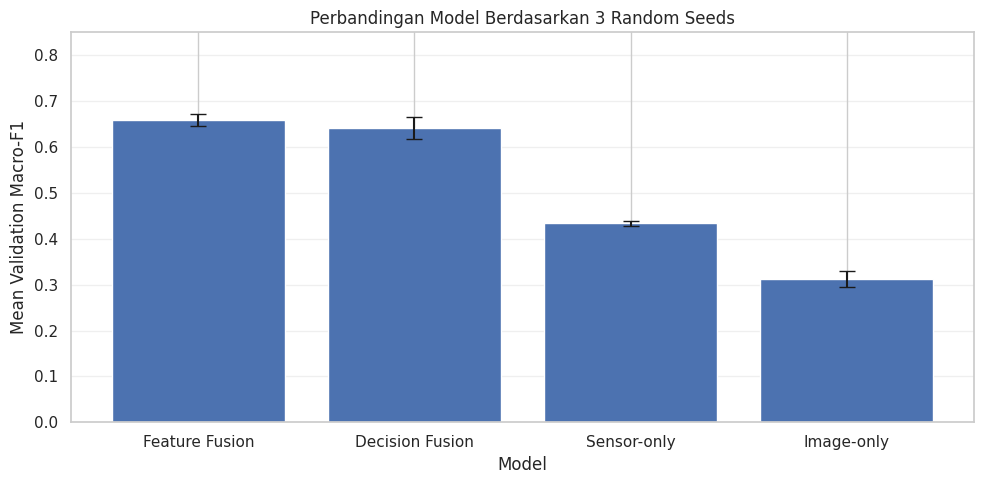

In [91]:

# 83. Grafik Final Perbandingan Model

plt.figure(figsize=(10, 5))

plt.bar(
    final_comparison_df["Model"],
    final_comparison_df["Mean Macro-F1"],
    yerr=final_comparison_df["Std Macro-F1"],
    capsize=6
)

plt.title("Perbandingan Model Berdasarkan 3 Random Seeds")
plt.ylabel("Mean Validation Macro-F1")
plt.xlabel("Model")
plt.ylim(0, 0.85)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


Notes :

Berdasarkan eksperimen menggunakan tiga random seed, Feature-level Fusion memperoleh performa terbaik dengan rata-rata Validation Macro-F1 sebesar 0,6591 dan standar deviasi 0,0126. Decision-level Fusion memperoleh rata-rata 0,6409, diikuti Sensor-only sebesar 0,4339 dan Image-only sebesar 0,3123. Hasil ini menunjukkan bahwa penggabungan fitur gambar dan sensor memberikan performa klasifikasi yang lebih baik dibandingkan penggunaan satu modalitas secara terpisah.

In [92]:

# 84. Menyimpan Model Final Feature Fusion

final_model = feature_seed_models[123]

torch.save(
    final_model.state_dict(),
    "feature_fusion_final.pth"
)

print("Model final berhasil disimpan.")
print("Model: Feature Fusion")
print("Seed: 123")
print("Validation Macro-F1: 0.6731")


Model final berhasil disimpan.
Model: Feature Fusion
Seed: 123
Validation Macro-F1: 0.6731


In [93]:

# 85. Memeriksa Checkpoint Model Final

import os

model_path = "feature_fusion_final.pth"

print("File tersedia:", os.path.exists(model_path))
print("Ukuran file:", round(os.path.getsize(model_path) / (1024**2), 2), "MB")


File tersedia: True
Ukuran file: 0.77 MB


###Menyiapkan Data Hidden Test

In [94]:

# 86. Menyiapkan Data Hidden Test

from torch.utils.data import TensorDataset, DataLoader

test_image_tensor = torch.tensor(
    X_image_test_normalized,
    dtype=torch.float32
).unsqueeze(1)

test_sensor_tensor = torch.tensor(
    X_sensor_test,
    dtype=torch.float32
)

test_dataset = TensorDataset(
    test_image_tensor,
    test_sensor_tensor
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

print("Jumlah data test:", len(test_dataset))
print("Jumlah batch:", len(test_loader))
print("Bentuk gambar:", test_image_tensor.shape)
print("Bentuk sensor:", test_sensor_tensor.shape)


Jumlah data test: 16000
Jumlah batch: 250
Bentuk gambar: torch.Size([16000, 1, 64, 64])
Bentuk sensor: torch.Size([16000, 3, 128])


In [95]:

# 87. Memuat Checkpoint Model Final

final_model = FeatureFusionModel().to(device)

final_model.load_state_dict(
    torch.load(
        "feature_fusion_final.pth",
        map_location=device
    )
)

final_model.eval()

print("Model Feature Fusion berhasil dimuat.")


Model Feature Fusion berhasil dimuat.


In [96]:

# 88. Prediksi Hidden Test

test_predictions = []

final_model.eval()

with torch.no_grad():
    for images, sensors in test_loader:

        images = images.to(device)
        sensors = sensors.to(device)

        outputs = final_model(images, sensors)

        predictions = outputs.argmax(dim=1)

        test_predictions.extend(
            predictions.cpu().numpy()
        )

test_predictions = np.array(test_predictions)

print("Jumlah prediksi:", len(test_predictions))
print("Distribusi prediksi kelas:")

for i, class_name in idx_to_class.items():
    count = np.sum(test_predictions == i)
    print(f"{class_name}: {count}")


Jumlah prediksi: 16000
Distribusi prediksi kelas:
gelembung: 1303
gores: 2604
kontaminasi: 540
las_dingin: 1483
noda: 2266
normal: 6745
retak: 1059


###Membuat CSV Submission

In [97]:

# 89. Memeriksa Metadata Test

print("Kolom metadata test:")
print(test_meta.columns.tolist())

print("\nContoh metadata test:")
display(test_meta.head())

print("\nJumlah metadata:", len(test_meta))
print("Jumlah prediksi:", len(test_predictions))

print("\nPemetaan label:")
print(idx_to_class)


Kolom metadata test:
['indeks', 'id_unit', 'lini', 'shift', 'id_mesin', 'batch_material']

Contoh metadata test:


,indeks,id_unit,lini,shift,id_mesin,batch_material
0,0,U412019,A,pagi,M01,B136
1,1,U929275,A,pagi,M01,B095
2,2,U845264,A,pagi,M01,B029
3,3,U382231,B,pagi,M08,B058
4,4,U156089,B,pagi,M12,B139



Jumlah metadata: 16000
Jumlah prediksi: 16000

Pemetaan label:
{0: 'gelembung', 1: 'gores', 2: 'kontaminasi', 3: 'las_dingin', 4: 'noda', 5: 'normal', 6: 'retak'}


In [98]:

# 89. Membuat CSV Submission Task 1

# Mengubah label numerik menjadi nama kelas
predicted_classes = [
    idx_to_class[int(pred)]
    for pred in test_predictions
]

# Membuat DataFrame sesuai format dosen
submission_df = pd.DataFrame({
    "id_unit": test_meta["id_unit"].values,
    "kelas": predicted_classes
})

# Menyimpan CSV
submission_df.to_csv(
    "prediksi_klasifikasi.csv",
    index=False
)

print("CSV berhasil dibuat!")
display(submission_df.head())


CSV berhasil dibuat!


,id_unit,kelas
0,U412019,normal
1,U929275,normal
2,U845264,gelembung
3,U382231,noda
4,U156089,normal


In [99]:

# 90. Validasi File Submission

submission_check = pd.read_csv("prediksi_klasifikasi.csv")

print("Nama kolom:", submission_check.columns.tolist())
print("Jumlah baris:", len(submission_check))
print("Jumlah ID unik:", submission_check["id_unit"].nunique())
print("Jumlah kelas valid:",
      submission_check["kelas"].isin(class_names).sum())

print("\nDistribusi kelas:")
print(submission_check["kelas"].value_counts())

print("\nContoh data:")
display(submission_check.head())

assert submission_check.columns.tolist() == ["id_unit", "kelas"]
assert len(submission_check) == 16000
assert submission_check["id_unit"].nunique() == 16000
assert submission_check["kelas"].isin(class_names).all()

print("\nSemua validasi berhasil!")


Nama kolom: ['id_unit', 'kelas']
Jumlah baris: 16000
Jumlah ID unik: 16000
Jumlah kelas valid: 16000

Distribusi kelas:
kelas
normal         6745
gores          2604
noda           2266
las_dingin     1483
gelembung      1303
retak          1059
kontaminasi     540
Name: count, dtype: int64

Contoh data:


,id_unit,kelas
0,U412019,normal
1,U929275,normal
2,U845264,gelembung
3,U382231,noda
4,U156089,normal



Semua validasi berhasil!


In [100]:

# 91. Download File Submission

from google.colab import files

files.download("prediksi_klasifikasi.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [101]:
# Download artefak Task 1

from google.colab import files

files.download("feature_fusion_final.pth")
files.download("prediksi_klasifikasi.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>